###WELCOME TO THE CADD PROJECT
This is a machine learning project aimed at drug discovery for Alzheimer's Disease. The goal is to predict which drug-like molecules (compounds) might inhibit proteins linked to Alzheimer's — based on how well they bind to those proteins.

## Install & Import libraries

In [ ]:
# Install required libraries
!pip install rdkit --quiet

# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# RDKit for molecular processing
from rdkit import Chem
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

# Sklearn for ML
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

print("All libraries imported successfully!")

All libraries imported successfully!


## Loading **Dataset**

In [ ]:
# Load the BindingDB dataset (tab-separated)
df = pd.read_csv("alzhiemers dataset.tsv", sep="\t", low_memory=False)

print("Dataset shape :", df.shape)
df.head()

Dataset shape : (9388, 640)


,BindingDB Reactant_set_id,Ligand SMILES,Ligand InChI,Ligand InChI Key,BindingDB MonomerID,BindingDB Ligand Name,Target Name,Target Source Organism According to Curator or DataSource,Ki (nM),IC50 (nM),...,UniProt (SwissProt) Recommended Name of Target Chain 50,UniProt (SwissProt) Entry Name of Target Chain 50,UniProt (SwissProt) Primary ID of Target Chain 50,UniProt (SwissProt) Secondary ID(s) of Target Chain 50,UniProt (SwissProt) Alternative ID(s) of Target Chain 50,UniProt (TrEMBL) Submitted Name of Target Chain 50,UniProt (TrEMBL) Entry Name of Target Chain 50,UniProt (TrEMBL) Primary ID of Target Chain 50,UniProt (TrEMBL) Secondary ID(s) of Target Chain 50,UniProt (TrEMBL) Alternative ID(s) of Target Chain 50
0,50352562,COc1ccc(cc1OC)C(C)NS(N)(=O)=O,"InChI=1S/C10H16N2O4S/c1-7(12-17(11,13)14)8-4-5...",XRTLNGOFVMCPQN-UHFFFAOYSA-N,50093582,CHEMBL3585782,Acetylcholinesterase,Homo sapiens,0.005,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,50352536,COc1ccc(cc1)C(C)NS(=O)(=O)NC(=O)OCc1ccccc1,InChI=1S/C17H20N2O5S/c1-13(15-8-10-16(23-2)11-...,GIRLQTWFPQINCE-UHFFFAOYSA-N,50093588,CHEMBL3585776,Acetylcholinesterase,Homo sapiens,0.005,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,50352538,COc1ccc(cc1OC)C(C)NS(=O)(=O)NC(=O)OCc1ccccc1,InChI=1S/C18H22N2O6S/c1-13(15-9-10-16(24-2)17(...,DYCJEZBPGBQOFM-UHFFFAOYSA-N,50093587,CHEMBL3585777,Acetylcholinesterase,Homo sapiens,0.005,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,50277132,Clc1ccc(cc1)-c1nc2ccc(cc2c2NCCCc12)C(=O)NCCCNc...,InChI=1S/C35H33Cl2N5O/c36-23-11-8-21(9-12-23)3...,NOBALTDRZBHVTJ-UHFFFAOYSA-N,50049862,CHEMBL3322232,Acetylcholinesterase,Homo sapiens,NaN,0.006000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,50352552,COc1ccc(OC)c(c1)C(C)NS(N)(=O)=O,"InChI=1S/C10H16N2O4S/c1-7(12-17(11,13)14)9-6-8...",JRGRJSIDGMYVHG-UHFFFAOYSA-N,50093581,CHEMBL3585783,Acetylcholinesterase,Homo sapiens,0.006,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Select relevant columns

In [ ]:
# We only need 3 columns:
# - Ligand SMILES  : molecule structure
# - IC50 (nM)      : binding potency (target variable)
# - BindingDB Reactant_set_id : molecule ID

df = df[["BindingDB Reactant_set_id", "Ligand SMILES", "IC50 (nM)"]].copy()

print("Shape after column selection :", df.shape)
df.head()

Shape after column selection : (6641, 3)


,BindingDB Reactant_set_id,Ligand SMILES,IC50 (nM)
0,50277132,Clc1ccc(cc1)-c1nc2ccc(cc2c2NCCCc12)C(=O)NCCCNc...,0.006
1,51283323,Clc1cccc2nc3CCCCc3c(NCCCCCCC(=O)NCCc3c[nH]c4cc...,0.008
2,15404,Clc1cc(Cl)c2c(NCCCCCCC(=O)NCCc3c[nH]c4ccccc34)...,0.008
3,51116782,COc1ccccc1C(=O)N1Cc2cc(NC(=O)c3cccc(Cl)c3)ccc2...,0.011
4,51116771,Clc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1c...,0.013


##  Clean the data

In [ ]:
# ── Step 1: Drop rows with missing values ─────────────────────────────────
df = df.dropna()
print("After dropping NaN       :", len(df))

# ── Step 2: Remove duplicate molecules ────────────────────────────────────
df = df.drop_duplicates(subset="Ligand SMILES")
print("After dropping duplicates :", len(df))

# ── Step 3: Clean IC50 column — remove >, <, ~ symbols ───────────────────
# Some IC50 values are stored as strings like '>3000' or '<100'
df["IC50 (nM)"] = (
    df["IC50 (nM)"]
    .astype(str)
    .str.replace(">", "", regex=False)
    .str.replace("<", "", regex=False)
    .str.replace("~", "", regex=False)
    .str.strip()
)

# ── Step 4: Convert IC50 to numeric (invalid → NaN) ───────────────────────
df["IC50 (nM)"] = pd.to_numeric(df["IC50 (nM)"], errors="coerce")

# ── Step 5: Drop rows where IC50 is still NaN after conversion ────────────
df = df.dropna(subset=["IC50 (nM)"])
print("After IC50 cleaning       :", len(df))

# ── Step 6: Reset index cleanly ───────────────────────────────────────────
df = df.reset_index(drop=True)

print("\nSample IC50 values:")
print(df["IC50 (nM)"].describe())

After dropping NaN       : 6641
After dropping duplicates : 6641
After IC50 cleaning       : 6641

Sample IC50 values:
count    6.641000e+03
mean     2.254901e+05
std      7.126683e+06
min      6.000000e-03
25%      1.600000e+02
50%      2.570400e+03
75%      1.880000e+04
max      5.690000e+08
Name: IC50 (nM), dtype: float64


## Convert IC50 to pIC50

Final dataset shape : (6641, 4)

pIC50 distribution:
count    6641.000000
mean        5.772353
std         1.520220
min         0.244888
25%         4.725842
50%         5.589999
75%         6.795880
max        11.221849
Name: pIC50, dtype: float64


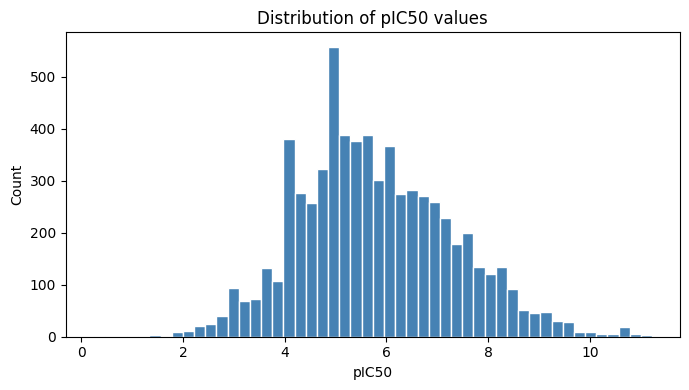

In [ ]:






# IC50 ranges from 1 to 1,000,000+ nM — too wide for ML
# pIC50 = -log10(IC50 in Molar) compresses this into a clean range
# Higher pIC50 = more potent compound

df["pIC50"] = -np.log10(df["IC50 (nM)"] / 1e9)

# Drop rows where pIC50 is NaN or infinite
df = df[df["pIC50"].notna() & np.isfinite(df["pIC50"])]
df = df.reset_index(drop=True)

print("Final dataset shape :", df.shape)
print("\npIC50 distribution:")
print(df["pIC50"].describe())

# Plot pIC50 distribution
plt.figure(figsize=(7, 4))
plt.hist(df["pIC50"], bins=50, color="steelblue", edgecolor="white")
plt.xlabel("pIC50")
plt.ylabel("Count")
plt.title("Distribution of pIC50 values")
plt.tight_layout()
plt.show()

In [ ]:
df

,BindingDB Reactant_set_id,Ligand SMILES,IC50 (nM),pIC50
0,50277132,Clc1ccc(cc1)-c1nc2ccc(cc2c2NCCCc12)C(=O)NCCCNc...,0.006,11.221849
1,51283323,Clc1cccc2nc3CCCCc3c(NCCCCCCC(=O)NCCc3c[nH]c4cc...,0.008,11.096910
2,15404,Clc1cc(Cl)c2c(NCCCCCCC(=O)NCCc3c[nH]c4ccccc34)...,0.008,11.096910
3,51116782,COc1ccccc1C(=O)N1Cc2cc(NC(=O)c3cccc(Cl)c3)ccc2...,0.011,10.958607
4,51116771,Clc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1c...,0.013,10.886057
...,...,...,...,...
6636,51416247,O=C(CCn1c2ccccc2c2cnccc12)N1c2ccccc2Sc2ccccc12,2300.000,5.638272
6637,51456312,Oc1cc2CC[n+]3cc4c(O)c(O)ccc4cc3-c2cc1O,2300.000,5.638272
6638,50881027,CCn1c2ccccc2c2cc(C=Cc3cc(N4CCOCC4)c4ccccc4[n+]...,2300.000,5.638272
6639,51322849,Oc1ccc(CNC2CCN(Cc3ccccc3)CC2)c(O)c1,2300.000,5.638272


## Convert SMILES to Morgan Fingerprints

In [ ]:
# Parse SMILES strings into RDKit mol objects
df["mol"] = df["Ligand SMILES"].apply(lambda x: Chem.MolFromSmiles(str(x)))

# Drop rows where SMILES could not be parsed
df = df[df["mol"].notnull()].reset_index(drop=True)
print("After mol parsing :", len(df))

# Generate Morgan Fingerprints
# radius=2 captures chemical neighbourhood within 2 bonds (standard for drug data)
# fpSize=2048 gives a 2048-bit binary vector per molecule
morgan_gen = GetMorganGenerator(radius=2, fpSize=2048)

fingerprints = []
for mol in df["mol"]:
    fp = morgan_gen.GetFingerprint(mol)
    fingerprints.append(fp.ToList())

print("Fingerprints generated :", len(fingerprints))

After mol parsing : 6640
Fingerprints generated : 6640


## Build final feature dataframe

In [ ]:
# Convert fingerprints list into a dataframe
fp_df = pd.DataFrame(fingerprints)

# Remove columns that are always 0 (zero variance — carry no information)
fp_df = fp_df.loc[:, (fp_df != 0).any(axis=0)]
print("Fingerprint columns after removing zero-variance :", fp_df.shape[1])

# Attach pIC50 as the target column
# Using .values ensures index alignment is position-based (safe)
fp_df["pIC50"] = df["pIC50"].values

# Final reset
fp_df = fp_df.reset_index(drop=True)

print("\nFinal dataframe shape :", fp_df.shape)
print("pIC50 nulls           :", fp_df["pIC50"].isna().sum())
fp_df.head()

Fingerprint columns after removing zero-variance : 2047

Final dataframe shape : (6640, 2048)
pIC50 nulls           : 0


,0,1,2,3,4,5,6,7,8,9,...,2039,2040,2041,2042,2043,2044,2045,2046,2047,pIC50
0,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,11.221849
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,11.096910
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,11.096910
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,10.958607
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,10.886057


## Train / Test split

In [ ]:
# Separate features (X) from target (y)
X = fp_df.drop(columns=["pIC50"])
y = fp_df["pIC50"]

# 80% training, 20% testing
# random_state=42 ensures reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples :", X_train.shape[0])
print("Testing samples  :", X_test.shape[0])
print("Features         :", X_train.shape[1])

Training samples : 5312
Testing samples  : 1328
Features         : 2047


## Define all model pipelines

In [ ]:
# Each pipeline = StandardScaler + Model
# StandardScaler normalises features — important for Linear, SVR, KNN
# Random Forest and Gradient Boosting don't strictly need it but it doesn't hurt

pipelines = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  Ridge(alpha=1.0))
    ]),
    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  Lasso(alpha=0.01, max_iter=5000))
    ]),
    "KNN Regressor": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  KNeighborsRegressor(n_neighbors=5))
    ]),
    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  SVR(kernel="rbf", C=10, epsilon=0.1))
    ]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
    ]),
    "Gradient Boosting": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42))
    ]),
}

print(f"{len(pipelines)} models ready to train.")

7 models ready to train.


## Train & evaluate all models

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, pipeline in pipelines.items():
    print(f"Training : {name} ...")

    # 5-fold cross validation on training set
    cv_scores = cross_val_score(
        pipeline, X_train, y_train, cv=kf, scoring="r2", n_jobs=-1
    )

    # Fit on full training set
    pipeline.fit(X_train, y_train)

    # Predict on test set
    y_pred    = pipeline.predict(X_test)
    test_r2   = r2_score(y_test, y_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results.append({
        "Model"      : name,
        "CV R² Mean" : round(cv_scores.mean(), 4),
        "CV R² Std"  : round(cv_scores.std(),  4),
        "Test R²"    : round(test_r2,           4),
        "Test RMSE"  : round(test_rmse,         4),
    })

    print(f"   CV R²: {cv_scores.mean():.4f} ± {cv_scores.std():.4f} | Test R²: {test_r2:.4f} | RMSE: {test_rmse:.4f}\n")

# Summary table sorted by Test R²
results_df = pd.DataFrame(results).sort_values("Test R²", ascending=False)
print("=" * 65)
print(results_df.to_string(index=False))

Training : Linear Regression ...
   CV R²: -0.1300 ± 0.1827 | Test R²: 0.3558 | RMSE: 1.2381

Training : Ridge Regression ...
   CV R²: -0.0815 ± 0.1667 | Test R²: 0.3636 | RMSE: 1.2307

Training : Lasso Regression ...
   CV R²: 0.6130 ± 0.0235 | Test R²: 0.6370 | RMSE: 0.9295

Training : KNN Regressor ...
   CV R²: 0.5719 ± 0.0221 | Test R²: 0.6361 | RMSE: 0.9306

Training : SVR ...
   CV R²: 0.6753 ± 0.0123 | Test R²: 0.7033 | RMSE: 0.8403

Training : Random Forest ...
   CV R²: 0.7069 ± 0.0170 | Test R²: 0.7283 | RMSE: 0.8041

Training : Gradient Boosting ...
   CV R²: 0.5096 ± 0.0297 | Test R²: 0.5367 | RMSE: 1.0500

            Model  CV R² Mean  CV R² Std  Test R²  Test RMSE
    Random Forest      0.7069     0.0170   0.7283     0.8041
              SVR      0.6753     0.0123   0.7033     0.8403
 Lasso Regression      0.6130     0.0235   0.6370     0.9295
    KNN Regressor      0.5719     0.0221   0.6361     0.9306
Gradient Boosting      0.5096     0.0297   0.5367     1.0500
 Ridg

## Visualise model comparison

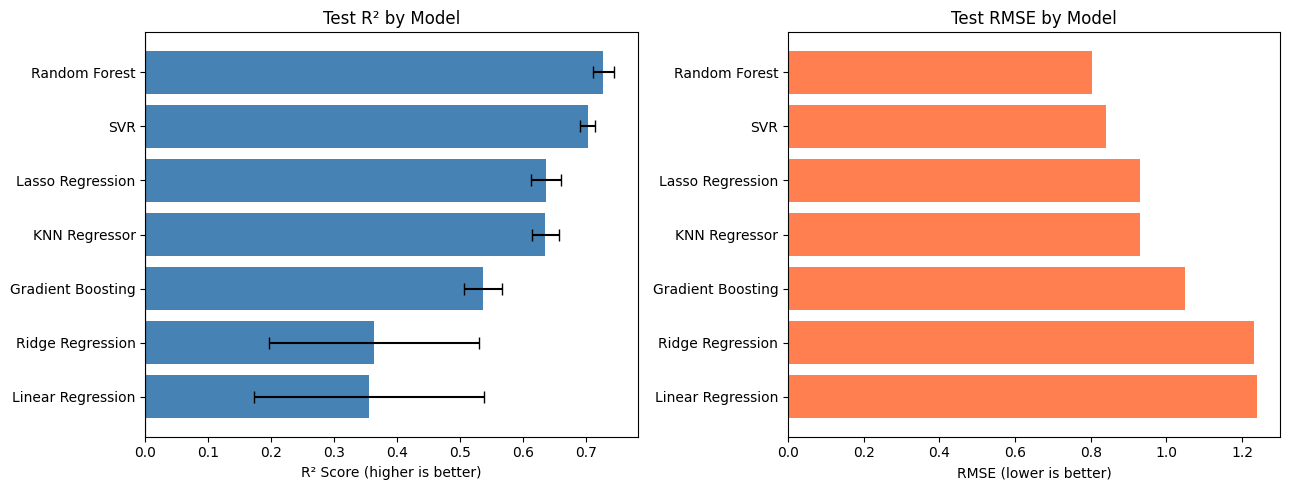

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# R² bar chart
axes[0].barh(results_df["Model"], results_df["Test R²"],
             xerr=results_df["CV R² Std"], color="steelblue", capsize=4)
axes[0].set_xlabel("R² Score (higher is better)")
axes[0].set_title("Test R² by Model")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].invert_yaxis()

# RMSE bar chart
axes[1].barh(results_df["Model"], results_df["Test RMSE"],
             color="coral")
axes[1].set_xlabel("RMSE (lower is better)")
axes[1].set_title("Test RMSE by Model")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()

## What are Molecular Descriptors?

Unlike fingerprints (which are binary yes/no features), molecular descriptors are actual numerical properties of a molecule — like molecular weight, number of hydrogen bond donors, lipophilicity, ring count etc. They give the model richer, more chemically meaningful information.


## Calculate Molecular Descriptors using RDKit
 Using RDKit has 200+ built-in descriptors. We calculate all of them for every molecule.

In [ ]:
from rdkit.Chem import Descriptors
from rdkit.ML.Descriptors import MoleculeDescriptors
import pandas as pd
import numpy as np

# Re-create the 'mol' column on the current df if it doesn't exist
# This ensures the RDKit molecule objects are available for descriptor calculation
if 'mol' not in df.columns:
    from rdkit import Chem
    df['mol'] = df['Ligand SMILES'].apply(lambda x: Chem.MolFromSmiles(str(x)))
    df = df[df['mol'].notnull()].reset_index(drop=True)
    print("Re-created 'mol' column.")

# Get list of all available descriptor names
descriptor_names = [name for name, _ in Descriptors.descList]
print(f"Total descriptors available: {len(descriptor_names)}")

# Create descriptor calculator
calculator = MoleculeDescriptors.MolecularDescriptorCalculator(descriptor_names)

# Calculate descriptors for every molecule
descriptor_values = []
for mol in df["mol"]:
    descriptors = calculator.CalcDescriptors(mol)
    descriptor_values.append(descriptors)

# Build dataframe
desc_df = pd.DataFrame(descriptor_values, columns=descriptor_names)
print("Descriptor dataframe shape:", desc_df.shape)
desc_df.head()

Re-created 'mol' column.
Total descriptors available: 217
Descriptor dataframe shape: (9380, 217)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_sulfide,fr_sulfonamd,fr_sulfone,fr_term_acetylene,fr_tetrazole,fr_thiazole,fr_thiocyan,fr_thiophene,fr_unbrch_alkane,fr_urea
0,10.903288,10.903288,0.439994,-3.728832,0.808878,13.176471,260.315,244.187,260.083078,96,...,0,0,0,0,0,0,0,0,0,0
1,12.011397,12.011397,0.017632,-4.054056,0.787294,12.240000,364.423,344.263,364.109293,134,...,0,0,0,0,0,0,0,0,0,0
2,12.134616,12.134616,0.034300,-4.114445,0.713187,12.111111,394.449,372.273,394.119857,146,...,0,0,0,0,0,0,0,0,0,0
3,13.202586,13.202586,0.074427,-0.074427,0.161941,14.186047,610.589,577.325,609.206216,218,...,0,0,0,0,0,0,0,0,0,0
4,10.963683,10.963683,0.504583,-3.762431,0.808878,13.176471,260.315,244.187,260.083078,96,...,0,0,0,0,0,0,0,0,0,0


## Clean the Descriptor Dataframe
Some descriptors produce NaN or infinite values for certain molecules. We drop those.

In [ ]:
# Replace infinities with NaN
desc_df = desc_df.replace([np.inf, -np.inf], np.nan)

# Drop columns where more than 10% of values are NaN
threshold = 0.1
desc_df = desc_df.dropna(thresh=int((1 - threshold) * len(desc_df)), axis=1)

# Drop remaining rows that still have NaN
desc_df = desc_df.dropna(axis=0).reset_index(drop=True)

print("After cleaning shape:", desc_df.shape)

After cleaning shape: (9371, 217)


## Remove Low Variance Features
Descriptors that barely change across molecules carry no useful information for the model.

In [ ]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.01)
desc_array = selector.fit_transform(desc_df)

selected_columns = desc_df.columns[selector.get_support()]
desc_df_clean = pd.DataFrame(desc_array, columns=selected_columns)

print("Before variance filter:", desc_df.shape[1], "features")
print("After variance filter :", desc_df_clean.shape[1], "features")

Before variance filter: 217 features
After variance filter : 186 features


## Attach pIC50
We need to align pIC50 with the cleaned descriptor rows carefully.
python

In [ ]:
import numpy as np
import pandas as pd
# Align pIC50 with desc_df_clean using df index

# Ensure 'pIC50' column exists in df
if "pIC50" not in df.columns:
    print("pIC50 column not found in df. Recreating it from 'IC50 (nM)'.")
    # Ensure IC50 is numeric in case the dataframe was reloaded/reset
    df["IC50 (nM)"] = pd.to_numeric(df["IC50 (nM)"], errors="coerce")
    # Drop any new NaNs created by conversion
    df = df.dropna(subset=["IC50 (nM)"])

    df["pIC50"] = -np.log10(df["IC50 (nM)"] / 1e9)
    # Drop rows where pIC50 is NaN or infinite after recreation
    df = df[df["pIC50"].notna() & np.isfinite(df["pIC50"])].reset_index(drop=True)

pic50_values = df["pIC50"].reset_index(drop=True)

# desc_df may have dropped some rows — reindex to match
desc_df_clean = desc_df_clean.reset_index(drop=True)
pic50_aligned = pic50_values.iloc[:len(desc_df_clean)].reset_index(drop=True)

desc_df_clean["pIC50"] = pic50_aligned

# Drop any remaining NaN in pIC50
desc_df_clean = desc_df_clean[
    desc_df_clean["pIC50"].notna() & np.isfinite(desc_df_clean["pIC50"])
].reset_index(drop=True)

print("Final dataset shape:", desc_df_clean.shape)
desc_df_clean.head()

pIC50 column not found in df. Recreating it from 'IC50 (nM)'.


/usr/local/lib/python3.12/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/tmp/ipykernel_4102/2146359524.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["pIC50"] = -np.log10(df["IC50 (nM)"] / 1e9)


Final dataset shape: (7286, 187)


,MaxAbsEStateIndex,MaxEStateIndex,MinAbsEStateIndex,MinEStateIndex,qed,SPS,MolWt,HeavyAtomMolWt,ExactMolWt,NumValenceElectrons,...,fr_priamide,fr_pyridine,fr_quatN,fr_sulfide,fr_sulfonamd,fr_term_acetylene,fr_thiazole,fr_thiophene,fr_unbrch_alkane,pIC50
0,10.903288,10.903288,0.439994,-3.728832,0.808878,13.176471,260.315,244.187,260.083078,96.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.221849
1,12.011397,12.011397,0.017632,-4.054056,0.787294,12.240000,364.423,344.263,364.109293,134.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.096910
2,12.134616,12.134616,0.034300,-4.114445,0.713187,12.111111,394.449,372.273,394.119857,146.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.096910
3,13.202586,13.202586,0.074427,-0.074427,0.161941,14.186047,610.589,577.325,609.206216,218.0,...,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.096910
4,10.963683,10.963683,0.504583,-3.762431,0.808878,13.176471,260.315,244.187,260.083078,96.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.958607


## Train / Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X = desc_df_clean.drop(columns=["pIC50"])
y = desc_df_clean["pIC50"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)

X_train shape: (5828, 186)
X_test shape : (1458, 186)


## Define All Model Pipelines

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

pipelines = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  Ridge(alpha=1.0))
    ]),
    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  Lasso(alpha=0.01, max_iter=5000))
    ]),
    "KNN Regressor": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  KNeighborsRegressor(n_neighbors=5))
    ]),
    "SVR": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  SVR(kernel="rbf", C=10, epsilon=0.1))
    ]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
    ]),
    "Gradient Boosting": Pipeline([
        ("scaler", StandardScaler()),
        ("model",  GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42))
    ]),
}

## Train & Cross-Validate All Models

In [ ]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error, r2_score

kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, pipeline in pipelines.items():
    print(f"Training: {name}...")

    # 5-fold cross validation
    cv_scores = cross_val_score(pipeline, X_train, y_train,
                                cv=kf, scoring="r2", n_jobs=-1)

    # Fit on full training set
    pipeline.fit(X_train, y_train)

    # Evaluate on test set
    y_pred    = pipeline.predict(X_test)
    test_r2   = r2_score(y_test, y_pred)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    results.append({
        "Model"      : name,
        "CV R² Mean" : round(cv_scores.mean(), 4),
        "CV R² Std"  : round(cv_scores.std(),  4),
        "Test R²"    : round(test_r2,           4),
        "Test RMSE"  : round(test_rmse,         4),
    })

    print(f"  CV R²: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  Test R²: {test_r2:.4f}  |  Test RMSE: {test_rmse:.4f}\n")

results_df = pd.DataFrame(results).sort_values("Test R²", ascending=False)
print("\n===== Model Comparison =====")
print(results_df.to_string(index=False))

Training: Linear Regression...
  CV R²: 0.0691 ± 0.0412
  Test R²: 0.0907  |  Test RMSE: 1.4479

Training: Ridge Regression...
  CV R²: 0.0747 ± 0.0318
  Test R²: 0.0888  |  Test RMSE: 1.4495

Training: Lasso Regression...
  CV R²: 0.0647 ± 0.0195
  Test R²: 0.0648  |  Test RMSE: 1.4684

Training: KNN Regressor...
  CV R²: 0.1003 ± 0.0211
  Test R²: 0.0868  |  Test RMSE: 1.4511

Training: SVR...
  CV R²: 0.1318 ± 0.0333
  Test R²: 0.1598  |  Test RMSE: 1.3918

Training: Random Forest...
  CV R²: 0.1709 ± 0.0164
  Test R²: 0.1815  |  Test RMSE: 1.3738

Training: Gradient Boosting...
  CV R²: 0.1334 ± 0.0155
  Test R²: 0.1587  |  Test RMSE: 1.3927


===== Model Comparison =====
            Model  CV R² Mean  CV R² Std  Test R²  Test RMSE
    Random Forest      0.1709     0.0164   0.1815     1.3738
              SVR      0.1318     0.0333   0.1598     1.3918
Gradient Boosting      0.1334     0.0155   0.1587     1.3927
Linear Regression      0.0691     0.0412   0.0907     1.4479
 Ridge Reg

## Visualise Model Comparison

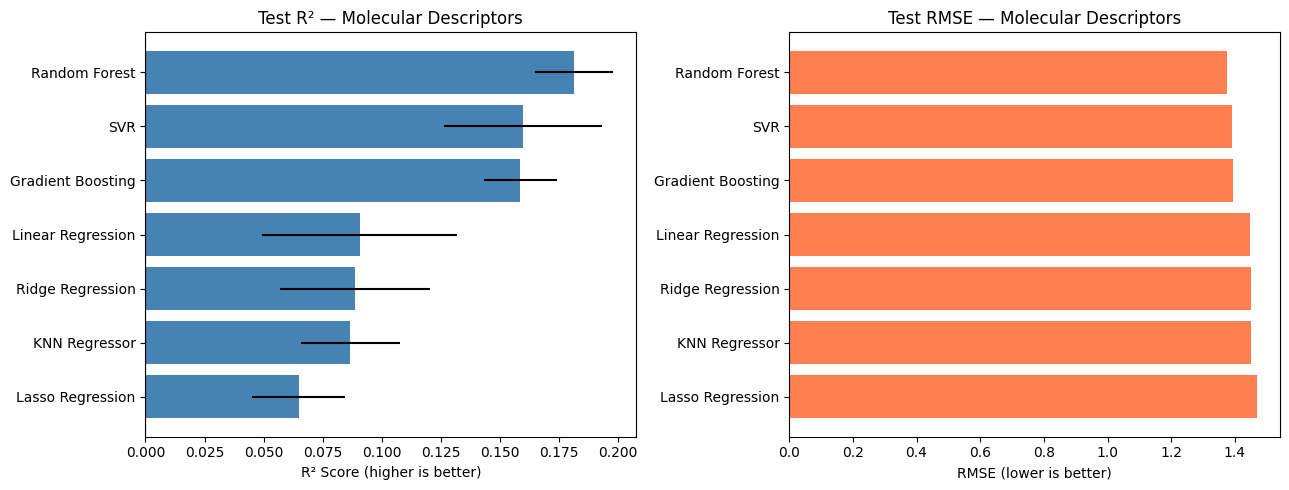

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].barh(results_df["Model"], results_df["Test R²"],
             xerr=results_df["CV R² Std"], color="steelblue")
axes[0].set_xlabel("R² Score (higher is better)")
axes[0].set_title("Test R² — Molecular Descriptors")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].invert_yaxis()

axes[1].barh(results_df["Model"], results_df["Test RMSE"], color="coral")
axes[1].set_xlabel("RMSE (lower is better)")
axes[1].set_title("Test RMSE — Molecular Descriptors")
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig("descriptor_model_comparison.png", dpi=150)
plt.show()

## Calculate Molecular Descriptors using Padelpy

In [ ]:
!pip install padelpy
from padelpy import from_smiles
import pandas as pd
import numpy as np
import time
import os

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.9/20.9 MB 26.0 MB/s eta 0:00:00


## Preparing the SMILES list (first 1650 rows)

In [ ]:
# Take rows 1 to 1650
df_1to1650  = df.iloc[0:1650].reset_index(drop=True)

smiles_list = df_1to1650["Ligand SMILES"].tolist()

print(f"Total SMILES to process: {len(smiles_list)}")
print("Sample:", smiles_list[0])

Total SMILES to process: 1650
Sample: Clc1ccc(cc1)-c1nc2ccc(cc2c2NCCCc12)C(=O)NCCCNc1c2CCCCc2nc2cc(Cl)ccc12


## ⚙️ Batch Processing Setup — Molecular Descriptor Generation

This section sets up the core pipeline for generating **PaDEL molecular descriptors** from SMILES strings using a batch processing approach.

### Why Batch Processing?
PaDEL-Descriptor processes each molecule individually through a Java engine, which is computationally intensive. To avoid:
- ⏱️ Session timeouts on Google Colab
- 💥 Memory crashes on large datasets
- ❌ Loss of progress on failure

...we split the full dataset into **smaller batches of 200 molecules each**, process them independently, and save a checkpoint CSV after every batch.

### What This Cell Does
| Component | Purpose |
|---|---|
| `split_into_batches()` | Dynamically splits SMILES list into batches of 200 |
| `generate_descriptors_for_batch()` | Runs PaDEL on one batch, molecule by molecule |
| **Checkpoint saving** | Saves `batch_N_checkpoint.csv` after each batch completes |
| **Progress saving** | Saves a temp file every 50 molecules within a batch |
| **Crash recovery** | Automatically skips batches that are already completed |



## Output
Each batch produces a CSV file:

In [ ]:
# DYNAMIC SPLIT — batch size 200
def split_into_batches(smiles_list, batch_size=200):
    total   = len(smiles_list)
    batches = [smiles_list[i : i + batch_size] for i in range(0, total, batch_size)]
    print(f"Total SMILES available : {total}")
    print(f"Batch size             : {batch_size}")
    print(f"Total batches created  : {len(batches)}")
    for idx, b in enumerate(batches):
        print(f"  Batch {idx+1} size: {len(b)}")
    return batches

batches = split_into_batches(smiles_list, batch_size=200)

# DESCRIPTOR GENERATION FUNCTION
def generate_descriptors_for_batch(batch_smiles, batch_num):
    save_file = f"batch_{batch_num}_checkpoint.csv"

    if os.path.exists(save_file):
        print(f"Batch {batch_num} already done — loading from checkpoint ✓")
        return pd.read_csv(save_file)

    print(f"\nProcessing Batch {batch_num} ({len(batch_smiles)} molecules)...")
    descriptor_rows = []
    failed          = 0

    for i, smi in enumerate(batch_smiles):
        try:
            result = from_smiles([smi], descriptors=True, fingerprints=False, timeout=60)
            row_df = pd.DataFrame(result)
            row_df.insert(0, "Ligand SMILES", smi)
            row_df.insert(1, "Batch", batch_num)
            descriptor_rows.append(row_df)
        except Exception as e:
            print(f"  PaDEL failed for row {i} ({smi[:30]}...): {e}")
            failed += 1

        if descriptor_rows and (i + 1) % 50 == 0:
            temp_df = pd.concat(descriptor_rows, ignore_index=True)
            temp_df.to_csv(f"batch_{batch_num}_temp.csv", index=False)
            print(f"  Progress: {i+1}/{len(batch_smiles)} saved ✓")

        time.sleep(0.3)

    print(f"  Batch {batch_num} done — success: {len(descriptor_rows)}, failed: {failed}")

    if descriptor_rows:
        final_df = pd.concat(descriptor_rows, ignore_index=True)
        final_df.to_csv(save_file, index=False)
        print(f"  ✓ Checkpoint saved: {save_file}")
        return final_df
    else:
        return pd.DataFrame()

print("\n✓ Setup complete — ready to run batch cells")

Total SMILES available : 1650
Batch size             : 200
Total batches created  : 9
  Batch 1 size: 200
  Batch 2 size: 200
  Batch 3 size: 200
  Batch 4 size: 200
  Batch 5 size: 200
  Batch 6 size: 200
  Batch 7 size: 200
  Batch 8 size: 200
  Batch 9 size: 50

✓ Setup complete — ready to run batch cells


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Batch 1 (rows 1–200)

In [ ]:
print("=" * 50)
print("CELL 1 — Batch 1 (rows 1–200)")
print("=" * 50)

desc_batch1 = generate_descriptors_for_batch(batches[0], batch_num=1)
print(f"\n✓ Batch 1 shape: {desc_batch1.shape if not desc_batch1.empty else 'empty'}")

### Batch 2 (rows 201–400)

In [ ]:
print("=" * 50)
print("CELL 2 — Batch 2 (rows 201–400)")
print("=" * 50)

desc_batch2 = generate_descriptors_for_batch(batches[1], batch_num=2)
print(f"\n✓ Batch 2 shape: {desc_batch2.shape if not desc_batch2.empty else 'empty'}")

###Batch 3 (rows 401–600)

In [ ]:
print("=" * 50)
print("CELL 3 — Batch 3 (rows 401–600)")
print("=" * 50)

desc_batch3 = generate_descriptors_for_batch(batches[2], batch_num=3)
print(f"\n✓ Batch 3 shape: {desc_batch3.shape if not desc_batch3.empty else 'empty'}")

###Batch 4 (rows 601–800)

In [ ]:
print("=" * 50)
print("CELL 4 — Batch 4 (rows 601–800)")
print("=" * 50)

desc_batch4 = generate_descriptors_for_batch(batches[3], batch_num=4)
print(f"\n✓ Batch 4 shape: {desc_batch4.shape if not desc_batch4.empty else 'empty'}")

###Batch 5 (rows 801–1000)

In [ ]:
print("=" * 50)
print("CELL 5 — Batch 5 (rows 801–1000)")
print("=" * 50)

desc_batch5 = generate_descriptors_for_batch(batches[4], batch_num=5)
print(f"\n✓ Batch 5 shape: {desc_batch5.shape if not desc_batch5.empty else 'empty'}")

###Batch 6 (rows 1001–1200)

In [ ]:
print("=" * 50)
print("CELL 6 — Batch 6 (rows 1001–1200)")
print("=" * 50)

desc_batch6 = generate_descriptors_for_batch(batches[5], batch_num=6)
print(f"\n✓ Batch 6 shape: {desc_batch6.shape if not desc_batch6.empty else 'empty'}")

###Batch 7 (rows 1201–1400)

In [ ]:
print("=" * 50)
print("CELL 7 — Batch 7 (rows 1201–1400)")
print("=" * 50)

desc_batch7 = generate_descriptors_for_batch(batches[6], batch_num=7) if len(batches) > 6 else pd.DataFrame()
print(f"\n✓ Batch 7 shape: {desc_batch7.shape if not desc_batch7.empty else 'empty'}")

### Batch 8 (rows 1401–1600)

In [ ]:
print("=" * 50)
print("CELL 8 — Batch 8 (rows 1401–1600)")
print("=" * 50)

desc_batch8 = generate_descriptors_for_batch(batches[7], batch_num=8) if len(batches) > 7 else pd.DataFrame()
print(f"\n✓ Batch 8 shape: {desc_batch8.shape if not desc_batch8.empty else 'empty'}")

###Batch 9 (rows 1601–1650)


In [ ]:
print("=" * 50)
print("CELL 9 — Batch 9 (rows 1601–1650)")
print("=" * 50)

desc_batch9 = generate_descriptors_for_batch(batches[8], batch_num=9) if len(batches) > 8 else pd.DataFrame()
print(f"\n✓ Batch 9 shape: {desc_batch9.shape if not desc_batch9.empty else 'empty'}")

###Combine, Clean, Attach pIC50, Save

In [ ]:
import os

print("=" * 50)
print("CELL 10 — Combine, Clean, Attach pIC50, Save")
print("=" * 50)

# ── STEP 1: Read all checkpoint CSVs ─────────────────────────
all_batches = []
for n in range(1, 10):
    f = f"batch_{n}_checkpoint.csv"
    if os.path.exists(f):
        batch_df = pd.read_csv(f)
        all_batches.append(batch_df)
        print(f"  Loaded {f} — shape: {batch_df.shape}")
    else:
        print(f"  Skipped {f} — not found")

# ── STEP 2: Concatenate ───────────────────────────────────────
combined_df = pd.concat(all_batches, ignore_index=True)
print(f"\nCombined shape (before cleaning) : {combined_df.shape}")
print(f"Total batches loaded             : {len(all_batches)}")

# ── STEP 3: Clean descriptors ─────────────────────────────────
def clean_descriptors(desc_df):
    meta_cols = ["Ligand SMILES", "Batch"]
    desc_cols = [c for c in desc_df.columns if c not in meta_cols]

    desc_df[desc_cols] = desc_df[desc_cols].apply(pd.to_numeric, errors="coerce")
    desc_df[desc_cols] = desc_df[desc_cols].replace([np.inf, -np.inf], np.nan)

    min_count = int(0.9 * len(desc_df))
    desc_df   = desc_df.dropna(subset=desc_cols, thresh=min_count, axis=0)
    desc_df   = desc_df.dropna(axis=1, how="all")

    desc_cols = [c for c in desc_df.columns if c not in meta_cols]
    desc_df   = desc_df.dropna(subset=desc_cols).reset_index(drop=True)

    print(f"After cleaning: {desc_df.shape}")
    return desc_df

final_desc_df = clean_descriptors(combined_df)

# ── STEP 4: Attach pIC50 via SMILES key ──────────────────────
pic50_map              = df_1to1650.set_index("Ligand SMILES")["pIC50"].to_dict()
final_desc_df["pIC50"] = final_desc_df["Ligand SMILES"].map(pic50_map)

final_desc_df = final_desc_df[
    final_desc_df["pIC50"].notna() & np.isfinite(final_desc_df["pIC50"])
].reset_index(drop=True)

print(f"\nFinal dataset shape : {final_desc_df.shape}")

# ── STEP 5: Save final CSV ────────────────────────────────────
final_desc_df.to_csv("padel_descriptors_1650.csv", index=False)
print("✓ Saved: padel_descriptors_1650.csv")

final_desc_df.head()

ANU GOPAL
# Take rows 1651 to 3300

In [ ]:
# Take rows 1651 to 3300
df_1651to3300 = df.iloc[1650:3300].reset_index(drop=True)

smiles_list = df_1651to3300["Ligand SMILES"].tolist()

print(f"Total SMILES to process: {len(smiles_list)}")
print("Sample:", smiles_list[0])

Batch 10(rows 1651–1850)

In [ ]:
print("=" * 50)
print("CELL 10 — Batch 10 (rows 1651–1850)")
print("=" * 50)

desc_batch10 = generate_descriptors_for_batch(batches[0], batch_num=10)
print(f"\n✓ Batch 10 shape: {desc_batch10.shape if not desc_batch10.empty else 'empty'}")

# Save to Google Drive (padel_batches folder)
from google.colab import drive
drive.mount('/content/drive')

output_path = '/content/drive/MyDrive/padel_batches/batch_10.csv'
desc_batch10.to_csv(output_path, index=False)

print(f"Saved to {output_path}")

Batch 11(rows 1851–2050)

In [ ]:
print("=" * 50)
print("CELL 11 — Batch 11 (rows 1851–2050)")
print("=" * 50)

desc_batch11 = generate_descriptors_for_batch(batches[1], batch_num=11)
print(f"\n✓ Batch 11 shape: {desc_batch11.shape if not desc_batch11.empty else 'empty'}")

# Save to Google Drive (padel_batches folder)
output_path = '/content/drive/MyDrive/padel_batches/batch_11.csv'
desc_batch11.to_csv(output_path, index=False)

print(f"Saved to {output_path}")

Batch 12(rows 2051–2250)

In [ ]:
print("=" * 50)
print("CELL 12 — Batch 12 (rows 2051–2250)")
print("=" * 50)

desc_batch12 = generate_descriptors_for_batch(batches[2], batch_num=12)
print(f"\n✓ Batch 12 shape: {desc_batch12.shape if not desc_batch12.empty else 'empty'}")

# Save to Google Drive (padel_batches folder)
output_path = '/content/drive/MyDrive/padel_batches/batch_12.csv'
desc_batch12.to_csv(output_path, index=False)

print(f"Saved to {output_path}")

Batch 13 (rows 2251–2450)

In [ ]:
print("=" * 50)
print("CELL 13 — Batch 13 (rows 2251–2450)")
print("=" * 50)

desc_batch13 = generate_descriptors_for_batch(batches[3], batch_num=13)
print(f"\n✓ Batch 13 shape: {desc_batch13.shape if not desc_batch13.empty else 'empty'}")

# Save to Google Drive (padel_batches folder)
output_path = '/content/drive/MyDrive/padel_batches/batch_13.csv'
desc_batch13.to_csv(output_path, index=False)

print(f"Saved to {output_path}")

Batch 14 (rows 2451–2650)

In [ ]:
print("=" * 50)
print("CELL 14 — Batch 14 (rows 2451–2650)")
print("=" * 50)

desc_batch14 = generate_descriptors_for_batch(batches[4], batch_num=14)
print(f"\n✓ Batch 14 shape: {desc_batch14.shape if not desc_batch14.empty else 'empty'}")

# Save to Google Drive (padel_batches folder)
output_path = '/content/drive/MyDrive/padel_batches/batch_14.csv'
desc_batch14.to_csv(output_path, index=False)

print(f"Saved to {output_path}")

Batch 15 (rows 2651–2850)

In [ ]:
print("=" * 50)
print("CELL 15 — Batch 15 (rows 2651–2850)")
print("=" * 50)

desc_batch15 = generate_descriptors_for_batch(batches[5], batch_num=15)
print(f"\n✓ Batch 15 shape: {desc_batch15.shape if not desc_batch15.empty else 'empty'}")

# Save to Google Drive (padel_batches folder)
output_path = '/content/drive/MyDrive/padel_batches/batch_15.csv'
desc_batch15.to_csv(output_path, index=False)

print(f"Saved to {output_path}")

Batch 16 (rows 2851–3050)

In [ ]:
print("=" * 50)
print("CELL 16 — Batch 16 (rows 2851–3050)")
print("=" * 50)

desc_batch16 = generate_descriptors_for_batch(batches[6], batch_num=16) if len(batches) > 6 else pd.DataFrame()
print(f"\n✓ Batch 16 shape: {desc_batch16.shape if not desc_batch16.empty else 'empty'}")

# Save to Google Drive (padel_batches folder)
if not desc_batch16.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_16.csv'
    desc_batch16.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 16 is empty, nothing saved.")

Batch 17 (rows 3051–3250)

In [ ]:
print("=" * 50)
print("CELL 17 — Batch 17 (rows 3051–3250)")
print("=" * 50)

desc_batch17 = generate_descriptors_for_batch(batches[7], batch_num=17) if len(batches) > 7 else pd.DataFrame()
print(f"\n✓ Batch 17 shape: {desc_batch17.shape if not desc_batch17.empty else 'empty'}")

# Save to Google Drive (padel_batches folder)
if not desc_batch17.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_17.csv'
    desc_batch17.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 17 is empty, nothing saved.")

Batch 18 (rows 3251–3300)

In [ ]:
print("=" * 50)
print("CELL 18 — Batch 18 (rows 3251–3300)")
print("=" * 50)

desc_batch18 = generate_descriptors_for_batch(batches[8], batch_num=18) if len(batches) > 8 else pd.DataFrame()
print(f"\n✓ Batch 18 shape: {desc_batch18.shape if not desc_batch18.empty else 'empty'}")

# Save to Google Drive (padel_batches folder)
if not desc_batch18.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_18.csv'
    desc_batch18.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 18 is empty, nothing saved.")

 ## Loading and Concatenating all the datasets

In [ ]:
import os
import numpy as np
import pandas as pd

print("=" * 50)
print("CELL — Combine, Clean, Attach pIC50, Save (1651–3300)")
print("=" * 50)

# ── STEP 1: Read all batch CSVs from Google Drive ────────────
base_path = "/content/drive/MyDrive/padel_batches/"

all_batches = []
for n in range(10, 19):   # Batch 10 → 18
    f = os.path.join(base_path, f"batch_{n}.csv")

    if os.path.exists(f):
        batch_df = pd.read_csv(f)
        all_batches.append(batch_df)
        print(f"  Loaded batch_{n}.csv — shape: {batch_df.shape}")
    else:
        print(f"  Skipped batch_{n}.csv — not found")

# ── STEP 2: Concatenate ─────────────────────────────────────
combined_df = pd.concat(all_batches, ignore_index=True)
print(f"\nCombined shape (before cleaning) : {combined_df.shape}")
print(f"Total batches loaded             : {len(all_batches)}")

# ── STEP 3: Clean descriptors ───────────────────────────────
def clean_descriptors(desc_df):
    meta_cols = ["Ligand SMILES", "Batch"]
    desc_cols = [c for c in desc_df.columns if c not in meta_cols]

    desc_df[desc_cols] = desc_df[desc_cols].apply(pd.to_numeric, errors="coerce")
    desc_df[desc_cols] = desc_df[desc_cols].replace([np.inf, -np.inf], np.nan)

    min_count = int(0.9 * len(desc_df))
    desc_df   = desc_df.dropna(subset=desc_cols, thresh=min_count, axis=0)
    desc_df   = desc_df.dropna(axis=1, how="all")

    desc_cols = [c for c in desc_df.columns if c not in meta_cols]
    desc_df   = desc_df.dropna(subset=desc_cols).reset_index(drop=True)

    print(f"After cleaning: {desc_df.shape}")
    return desc_df

final_desc_df = clean_descriptors(combined_df)

# ── STEP 4: Attach pIC50 via SMILES key ─────────────────────
pic50_map = df_1651to3300.set_index("Ligand SMILES")["pIC50"].to_dict()

final_desc_df["pIC50"] = final_desc_df["Ligand SMILES"].map(pic50_map)

final_desc_df = final_desc_df[
    final_desc_df["pIC50"].notna() & np.isfinite(final_desc_df["pIC50"])
].reset_index(drop=True)

print(f"\nFinal dataset shape : {final_desc_df.shape}")

# ── STEP 5: Save final CSV to Drive ─────────────────────────
output_path = os.path.join(base_path, "padel_descriptors_1651_3300.csv")
final_desc_df.to_csv(output_path, index=False)

print(f"✓ Saved: {output_path}")

final_desc_df.head()

Sreekutty

# Take rows 3301 to 4951

In [ ]:
# Take rows 3301 to 4951
df_3301to4951 = df.iloc[3300:4951].reset_index(drop=True)

smiles_list = df_3301to4951["Ligand SMILES"].tolist()

print(f"Total SMILES to process: {len(smiles_list)}")
print("Sample:", smiles_list[0])


CELL 19 — Batch 19(rows 3300–3500)

In [ ]:
# CELL 19
print("=" * 50)
print("CELL 19 — Batch 19 (rows 3301–3500)")
print("=" * 50)

desc_batch19 = generate_descriptors_for_batch(batches[0], batch_num=19) if len(batches) > 0 else pd.DataFrame()
print(f"\n✓ Batch 19 shape: {desc_batch19.shape if not desc_batch19.empty else 'empty'}")

if not desc_batch19.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_19.csv'
    desc_batch19.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 19 is empty, nothing saved.")

cell 20 — Batch 2 (rows 3501–3700)

In [ ]:
# CELL 20
print("=" * 50)
print("CELL 20 — Batch 20 (rows 3501–3700)")
print("=" * 50)

desc_batch20 = generate_descriptors_for_batch(batches[1], batch_num=20) if len(batches) > 1 else pd.DataFrame()
print(f"\n✓ Batch 20 shape: {desc_batch20.shape if not desc_batch20.empty else 'empty'}")

if not desc_batch20.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_20.csv'
    desc_batch20.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 20 is empty, nothing saved.")


cell 21 — Batch 21 (rows 3701–3900)

In [ ]:
# CELL 21
print("=" * 50)
print("CELL 21 — Batch 21 (rows 3701–3900)")
print("=" * 50)

desc_batch21 = generate_descriptors_for_batch(batches[2], batch_num=21) if len(batches) > 2 else pd.DataFrame()
print(f"\n✓ Batch 21 shape: {desc_batch21.shape if not desc_batch21.empty else 'empty'}")

if not desc_batch21.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_21.csv'
    desc_batch21.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 21 is empty, nothing saved.")

CELL 22— Batch 22(rows 3901–4100)

In [ ]:
# CELL 22
print("=" * 50)
print("CELL 22 — Batch 22 (rows 3901–4100)")
print("=" * 50)

desc_batch22 = generate_descriptors_for_batch(batches[3], batch_num=22) if len(batches) > 3 else pd.DataFrame()
print(f"\n✓ Batch 22 shape: {desc_batch22.shape if not desc_batch22.empty else 'empty'}")

if not desc_batch22.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_22.csv'
    desc_batch22.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 22 is empty, nothing saved.")

CELL 23 — Batch 23 (rows 4101–4300)

In [ ]:
# CELL 23
print("=" * 50)
print("CELL 23 — Batch 23 (rows 4101–4300)")
print("=" * 50)

desc_batch23 = generate_descriptors_for_batch(batches[4], batch_num=23) if len(batches) > 4 else pd.DataFrame()
print(f"\n✓ Batch 23 shape: {desc_batch23.shape if not desc_batch23.empty else 'empty'}")

if not desc_batch23.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_23.csv'
    desc_batch23.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 23 is empty, nothing saved.")

CELL 24 — Batch 24 (rows 4301–4500)

In [ ]:
# CELL 24
print("=" * 50)
print("CELL 24 — Batch 24 (rows 4301–4500)")
print("=" * 50)

desc_batch24 = generate_descriptors_for_batch(batches[5], batch_num=24) if len(batches) > 5 else pd.DataFrame()
print(f"\n✓ Batch 24 shape: {desc_batch24.shape if not desc_batch24.empty else 'empty'}")

if not desc_batch24.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_24.csv'
    desc_batch24.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 24 is empty, nothing saved.")

CELL 25 — Batch 25 (rows 4501–4700)

In [ ]:
# CELL 25
print("=" * 50)
print("CELL 25 — Batch 25 (rows 4501–4700)")
print("=" * 50)

desc_batch25 = generate_descriptors_for_batch(batches[6], batch_num=25) if len(batches) > 6 else pd.DataFrame()
print(f"\n✓ Batch 25 shape: {desc_batch25.shape if not desc_batch25.empty else 'empty'}")

if not desc_batch25.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_25.csv'
    desc_batch25.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 25 is empty, nothing saved.")

CELL 26— Batch 26 (rows 4701–4900)

In [ ]:
# CELL 26
print("=" * 50)
print("CELL 26 — Batch 26 (rows 4701–4900)")
print("=" * 50)

desc_batch26 = generate_descriptors_for_batch(batches[7], batch_num=26) if len(batches) > 7 else pd.DataFrame()
print(f"\n✓ Batch 26 shape: {desc_batch26.shape if not desc_batch26.empty else 'empty'}")

if not desc_batch26.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_26.csv'
    desc_batch26.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 26 is empty, nothing saved.")

CELL 27 — Batch 9 (rows 4901–4951)

In [ ]:
# CELL 27
print("=" * 50)
print("CELL 27 — Batch 27 (rows 4901–4951)")
print("=" * 50)

desc_batch27 = generate_descriptors_for_batch(batches[8], batch_num=27) if len(batches) > 8 else pd.DataFrame()
print(f"\n✓ Batch 27 shape: {desc_batch27.shape if not desc_batch27.empty else 'empty'}")

if not desc_batch27.empty:
    output_path = '/content/drive/MyDrive/padel_batches/batch_27.csv'
    desc_batch27.to_csv(output_path, index=False)
    print(f"Saved to {output_path}")
else:
    print("Batch 27 is empty, nothing saved.")

Combine, Clean, Attach pIC50, Save

In [ ]:
import os
import numpy as np
import pandas as pd

print("=" * 50)
print("CELL — Combine, Clean, Attach pIC50, Save (3301–4951)")
print("=" * 50)

# ── STEP 1: Read all batch CSVs from Google Drive ────────────
base_path = "/content/drive/MyDrive/padel_batches/"

all_batches = []
for n in range(19, 28):   # Batch 19 → 27
    # FIX: Change the filename pattern to match what was saved to Google Drive
    f = os.path.join(base_path, f"batch_{n}.csv")

    if os.path.exists(f):
        batch_df = pd.read_csv(f)
        all_batches.append(batch_df)
        print(f"  Loaded batch_{n}.csv — shape: {batch_df.shape}")
    else:
        print(f"  Skipped batch_{n}.csv — not found")

# ── STEP 2: Concatenate ─────────────────────────────────────
combined_df = pd.concat(all_batches, ignore_index=True)
print(f"\nCombined shape (before cleaning) : {combined_df.shape}")
print(f"Total batches loaded             : {len(all_batches)}")

# ── STEP 3: Clean descriptors ───────────────────────────────
def clean_descriptors(desc_df):
    meta_cols = ["Ligand SMILES", "Batch"]
    desc_cols = [c for c in desc_df.columns if c not in meta_cols]

    desc_df[desc_cols] = desc_df[desc_cols].apply(pd.to_numeric, errors="coerce")
    desc_df[desc_cols] = desc_df[desc_cols].replace([np.inf, -np.inf], np.nan)

    min_count = int(0.9 * len(desc_df))
    desc_df = desc_df.dropna(subset=desc_cols, thresh=min_count, axis=0)
    desc_df = desc_df.dropna(axis=1, how="all")

    desc_cols = [c for c in desc_df.columns if c not in meta_cols]
    desc_df = desc_df.dropna(subset=desc_cols).reset_index(drop=True)

    print(f"After cleaning: {desc_df.shape}")
    return desc_df

final_desc_df = clean_descriptors(combined_df)

# ── STEP 4: Attach pIC50 via SMILES key ─────────────────────
pic50_map = df_3301to4951.set_index("Ligand SMILES")["pIC50"].to_dict()

final_desc_df["pIC50"] = final_desc_df["Ligand SMILES"].map(pic50_map)

final_desc_df = final_desc_df[
    final_desc_df["pIC50"].notna() & np.isfinite(final_desc_df["pIC50"])
].reset_index(drop=True)

print(f"\nFinal dataset shape : {final_desc_df.shape}")

# ── STEP 5: Save final CSV to Drive ─────────────────────────
output_path = os.path.join(base_path, "padel_descriptors_3301_4951.csv")
final_desc_df.to_csv(output_path, index=False)

print(f"✓ Saved: {output_path}")

final_desc_df.head()

Yadhu
# Take rows 4951 to 6640

In [ ]:
# Take rows 4951 to 6640
df_4951to6640 = df.iloc[4951:6640].reset_index(drop=True)
smiles_list   = df_4951to6640["Ligand SMILES"].tolist()

print(f"Total SMILES to process : {len(smiles_list)}")
print(f"Sample                  : {smiles_list[0]}")

Batch 28 (rows 4951–5150)

In [ ]:
# CELL 28
print("=" * 50)
print("CELL 28 — Batch 28 (rows 4951–5150)")
print("=" * 50)

start = time.time()
desc_batch28 = generate_descriptors_for_batch(batches[0], batch_num=28) if len(batches) > 0 else pd.DataFrame()
elapsed = time.time() - start

print(f"\n✓ Batch 28 shape: {desc_batch28.shape if not desc_batch28.empty else 'empty'}")

if not desc_batch28.empty:
    print(f"  Molecules   : {desc_batch28.shape[0]}")
    print(f"  Descriptors : {desc_batch28.shape[1] - 2}")
    print(f"  Time taken  : {elapsed/60:.1f} min")
    output_path = '/content/drive/MyDrive/padel_batches/batch_28.csv'
    desc_batch28.to_csv(output_path, index=False)
    print(f"  Saved to    : {output_path}")
else:
    print("Batch 28 is empty, nothing saved.")

batch 29 (rows 5151–5350)

In [ ]:
# CELL 29
print("=" * 50)
print("CELL 29 — Batch 29 (rows 5151–5350)")
print(f"  Total SMILES in this batch : {len(batches[1])}")
print("=" * 50)

start = time.time()
desc_batch29 = generate_descriptors_for_batch(batches[1], batch_num=29) if len(batches) > 1 else pd.DataFrame()
elapsed = time.time() - start

print(f"\n✓ Batch 29 shape: {desc_batch29.shape if not desc_batch29.empty else 'empty'}")

if not desc_batch29.empty:
    print(f"  Molecules   : {desc_batch29.shape[0]}")
    print(f"  Descriptors : {desc_batch29.shape[1] - 2}")
    print(f"  Time taken  : {elapsed/60:.1f} min")
    output_path = '/content/drive/MyDrive/padel_batches/batch_29.csv'
    desc_batch29.to_csv(output_path, index=False)
    print(f"  Saved to    : {output_path}")
else:
    print("Batch 29 is empty, nothing saved.")

Batch 30 (rows 5351–5550)

In [ ]:
# CELL 30
print("=" * 50)
print("CELL 30 — Batch 30 (rows 5351–5550)")
print(f"  Total SMILES in this batch : {len(batches[2])}")
print("=" * 50)

start = time.time()
desc_batch30 = generate_descriptors_for_batch(batches[2], batch_num=30) if len(batches) > 2 else pd.DataFrame()
elapsed = time.time() - start

print(f"\n✓ Batch 30 shape: {desc_batch30.shape if not desc_batch30.empty else 'empty'}")

if not desc_batch30.empty:
    print(f"  Molecules   : {desc_batch30.shape[0]}")
    print(f"  Descriptors : {desc_batch30.shape[1] - 2}")
    print(f"  Time taken  : {elapsed/60:.1f} min")
    output_path = '/content/drive/MyDrive/padel_batches/batch_30.csv'
    desc_batch30.to_csv(output_path, index=False)
    print(f"  Saved to    : {output_path}")
else:
    print("Batch 30 is empty, nothing saved.")

Batch 31 (rows 5551–5750)

In [ ]:
# CELL 31
print("=" * 50)
print("CELL 31 — Batch 31 (rows 5551–5750)")
print(f"  Total SMILES in this batch : {len(batches[3])}")
print("=" * 50)

start = time.time()
desc_batch31 = generate_descriptors_for_batch(batches[3], batch_num=31) if len(batches) > 3 else pd.DataFrame()
elapsed = time.time() - start

print(f"\n✓ Batch 31 shape: {desc_batch31.shape if not desc_batch31.empty else 'empty'}")

if not desc_batch31.empty:
    print(f"  Molecules   : {desc_batch31.shape[0]}")
    print(f"  Descriptors : {desc_batch31.shape[1] - 2}")
    print(f"  Time taken  : {elapsed/60:.1f} min")
    output_path = '/content/drive/MyDrive/padel_batches/batch_31.csv'
    desc_batch31.to_csv(output_path, index=False)
    print(f"  Saved to    : {output_path}")
else:
    print("Batch 31 is empty, nothing saved.")

Batch 32 (rows 5751–5950)

In [ ]:
# CELL 32
print("=" * 50)
print("CELL 32 — Batch 32 (rows 5751–5950)")
print(f"  Total SMILES in this batch : {len(batches[4])}")
print("=" * 50)

start = time.time()
desc_batch32 = generate_descriptors_for_batch(batches[4], batch_num=32) if len(batches) > 4 else pd.DataFrame()
elapsed = time.time() - start

print(f"\n✓ Batch 32 shape: {desc_batch32.shape if not desc_batch32.empty else 'empty'}")

if not desc_batch32.empty:
    print(f"  Molecules   : {desc_batch32.shape[0]}")
    print(f"  Descriptors : {desc_batch32.shape[1] - 2}")
    print(f"  Time taken  : {elapsed/60:.1f} min")
    output_path = '/content/drive/MyDrive/padel_batches/batch_32.csv'
    desc_batch32.to_csv(output_path, index=False)
    print(f"  Saved to    : {output_path}")
else:
    print("Batch 32 is empty, nothing saved.")

Batch 33 (rows 5951–6150)

In [ ]:
# CELL 33
print("=" * 50)
print("CELL 33 — Batch 33 (rows 5951–6150)")
print(f"  Total SMILES in this batch : {len(batches[5])}")
print("=" * 50)

start = time.time()
desc_batch33 = generate_descriptors_for_batch(batches[5], batch_num=33) if len(batches) > 5 else pd.DataFrame()
elapsed = time.time() - start

print(f"\n✓ Batch 33 shape: {desc_batch33.shape if not desc_batch33.empty else 'empty'}")

if not desc_batch33.empty:
    print(f"  Molecules   : {desc_batch33.shape[0]}")
    print(f"  Descriptors : {desc_batch33.shape[1] - 2}")
    print(f"  Time taken  : {elapsed/60:.1f} min")
    output_path = '/content/drive/MyDrive/padel_batches/batch_33.csv'
    desc_batch33.to_csv(output_path, index=False)
    print(f"  Saved to    : {output_path}")
else:
    print("Batch 33 is empty, nothing saved.")

Batch 34 (rows 6151–6350)")

In [ ]:
# CELL 34
print("=" * 50)
print("CELL 34 — Batch 34 (rows 6151–6350)")
print(f"  Total SMILES in this batch : {len(batches[6]) if len(batches) > 6 else 0}")
print("=" * 50)

start = time.time()
desc_batch34 = generate_descriptors_for_batch(batches[6], batch_num=34) if len(batches) > 6 else pd.DataFrame()
elapsed = time.time() - start

print(f"\n✓ Batch 34 shape: {desc_batch34.shape if not desc_batch34.empty else 'empty'}")

if not desc_batch34.empty:
    print(f"  Molecules   : {desc_batch34.shape[0]}")
    print(f"  Descriptors : {desc_batch34.shape[1] - 2}")
    print(f"  Time taken  : {elapsed/60:.1f} min")
    output_path = '/content/drive/MyDrive/padel_batches/batch_34.csv'
    desc_batch34.to_csv(output_path, index=False)
    print(f"  Saved to    : {output_path}")
else:
    print("Batch 34 is empty, nothing saved.")

Batch 35 (rows 6351–6550)

In [ ]:
# CELL 35
print("=" * 50)
print("CELL 35 — Batch 35 (rows 6351–6550)")
print(f"  Total SMILES in this batch : {len(batches[7]) if len(batches) > 7 else 0}")
print("=" * 50)

start = time.time()
desc_batch35 = generate_descriptors_for_batch(batches[7], batch_num=35) if len(batches) > 7 else pd.DataFrame()
elapsed = time.time() - start

print(f"\n✓ Batch 35 shape: {desc_batch35.shape if not desc_batch35.empty else 'empty'}")

if not desc_batch35.empty:
    print(f"  Molecules   : {desc_batch35.shape[0]}")
    print(f"  Descriptors : {desc_batch35.shape[1] - 2}")
    print(f"  Time taken  : {elapsed/60:.1f} min")
    output_path = '/content/drive/MyDrive/padel_batches/batch_35.csv'
    desc_batch35.to_csv(output_path, index=False)
    print(f"  Saved to    : {output_path}")
else:
    print("Batch 35 is empty, nothing saved.")

Batch 36 (rows 6551–6640)

In [ ]:
# CELL 36 — LAST BATCH
print("=" * 50)
print("CELL 36 — Batch 36 (rows 6551–6640)  ← Last batch (89 SMILES)")
print(f"  Total SMILES in this batch : {len(batches[8]) if len(batches) > 8 else 0}")
print("=" * 50)

start = time.time()
desc_batch36 = generate_descriptors_for_batch(batches[8], batch_num=36) if len(batches) > 8 else pd.DataFrame()
elapsed = time.time() - start

print(f"\n✓ Batch 36 shape: {desc_batch36.shape if not desc_batch36.empty else 'empty'}")

if not desc_batch36.empty:
    print(f"  Molecules   : {desc_batch36.shape[0]}")
    print(f"  Descriptors : {desc_batch36.shape[1] - 2}")
    print(f"  Time taken  : {elapsed/60:.1f} min")
    output_path = '/content/drive/MyDrive/padel_batches/batch_36.csv'
    desc_batch36.to_csv(output_path, index=False)
    print(f"  Saved to    : {output_path}")
else:
    print("Batch 36 is empty, nothing saved.")

Combine, Clean, Attach pIC50, Save

In [ ]:
import os
import numpy as np
import pandas as pd

print("=" * 50)
print("CELL — Combine, Clean, Attach pIC50, Save (4951–6640)")
print("=" * 50)

# ── STEP 1: Read all batch CSVs from Google Drive ────────────
base_path = "/content/drive/MyDrive/padel_batches/"

all_batches = []
for n in range(28, 37):   # Batch 28 → 36
    f = os.path.join(base_path, f"batch_{n}.csv")

    if os.path.exists(f):
        batch_df = pd.read_csv(f)
        all_batches.append(batch_df)
        print(f"  Loaded batch_{n}.csv — shape: {batch_df.shape}")
    else:
        print(f"  Skipped batch_{n}.csv — not found")

# ── STEP 2: Concatenate ─────────────────────────────────────
combined_df = pd.concat(all_batches, ignore_index=True)
print(f"\nCombined shape (before cleaning) : {combined_df.shape}")
print(f"Total batches loaded             : {len(all_batches)}")

# ── STEP 3: Clean descriptors ───────────────────────────────
def clean_descriptors(desc_df):
    meta_cols = ["Ligand SMILES", "Batch"]
    desc_cols = [c for c in desc_df.columns if c not in meta_cols]

    desc_df[desc_cols] = desc_df[desc_cols].apply(pd.to_numeric, errors="coerce")
    desc_df[desc_cols] = desc_df[desc_cols].replace([np.inf, -np.inf], np.nan)

    min_count = int(0.9 * len(desc_df))
    desc_df   = desc_df.dropna(subset=desc_cols, thresh=min_count, axis=0)
    desc_df   = desc_df.dropna(axis=1, how="all")

    desc_cols = [c for c in desc_df.columns if c not in meta_cols]
    desc_df   = desc_df.dropna(subset=desc_cols).reset_index(drop=True)

    print(f"After cleaning: {desc_df.shape}")
    return desc_df

final_desc_df = clean_descriptors(combined_df)

# ── STEP 4: Attach pIC50 via SMILES key ─────────────────────
pic50_map = df_4951to6640.set_index("Ligand SMILES")["pIC50"].to_dict()

final_desc_df["pIC50"] = final_desc_df["Ligand SMILES"].map(pic50_map)

matched   = final_desc_df["pIC50"].notna().sum()
unmatched = final_desc_df["pIC50"].isna().sum()
print(f"\n  pIC50 matched   : {matched}")
print(f"  pIC50 unmatched : {unmatched}")

final_desc_df = final_desc_df[
    final_desc_df["pIC50"].notna() & np.isfinite(final_desc_df["pIC50"])
].reset_index(drop=True)

print(f"\nFinal dataset shape : {final_desc_df.shape}")

# ── STEP 5: Save final CSV to Drive ─────────────────────────
output_path = os.path.join(base_path, "padel_descriptors_4951_6640.csv")
final_desc_df.to_csv(output_path, index=False)

print(f"✓ Saved: {output_path}")

final_desc_df.head()

 ## Load & Concatenate 4 CSV Files

In [ ]:
import numpy as np
import pandas as pd

print("=" * 60)
print(" Load & Concatenate 4 Batch CSVs")
print("=" * 60)

# ── Load all 4 files directly ─────────────────────────────────
df1 = pd.read_csv("padel_descriptors_1650.csv")
df2 = pd.read_csv("padel_descriptors_1651_3300.csv")
df3 = pd.read_csv("padel_descriptors_3301_4951.csv")
df4 = pd.read_csv("padel_descriptors_4951_to_6640.csv")

print(f"  Batch 1 shape : {df1.shape}")
print(f"  Batch 2 shape : {df2.shape}")
print(f"  Batch 3 shape : {df3.shape}")
print(f"  Batch 4 shape : {df4.shape}")

# ── Concatenate ───────────────────────────────────────────────
combined_df = pd.concat([df1, df2, df3, df4], ignore_index=True)

print(f"\n✓ Combined shape  : {combined_df.shape}")
print(f"  Total rows      : {combined_df.shape[0]}")
print(f"  Total columns   : {combined_df.shape[1]}")
print(f"  pIC50 present   : {'pIC50' in combined_df.columns}")
print(f"  NaN count       : {combined_df.isnull().sum().sum()}")
combined_df.head()

 Load & Concatenate 4 Batch CSVs
  Batch 1 shape : (1085, 1878)
  Batch 2 shape : (1107, 1878)
  Batch 3 shape : (983, 1878)
  Batch 4 shape : (1162, 1878)

✓ Combined shape  : (4337, 1878)
  Total rows      : 4337
  Total columns   : 1878
  pIC50 present   : True
  NaN count       : 0


,Ligand SMILES,Batch,nAcid,ALogP,ALogp2,AMR,apol,naAromAtom,nAromBond,nAtom,...,P2s,E1s,E2s,E3s,Ts,As,Vs,Ks,Ds,pIC50
0,COc1ccccc1C(=O)N1Cc2cc(NC(=O)c3cccc(Cl)c3)ccc2...,1,0,-0.6542,0.427978,42.0173,62.497067,18,18,50,...,0.187593,0.511065,0.395014,0.346120,17.282083,66.391943,151.347562,0.571907,1.252200,10.958607
1,Clc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1c...,1,0,-0.6024,0.362886,34.7015,58.601481,18,18,46,...,0.162336,0.554812,0.396024,0.410052,18.923095,73.206997,167.433870,0.618824,1.360888,10.886057
2,Cc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1cc...,1,0,-0.0627,0.003931,40.0901,63.275446,18,18,52,...,0.147658,0.569022,0.475498,0.498453,21.362618,93.497201,228.611707,0.619729,1.542973,10.853872
3,Cc1cccc(c1)C(=O)N1Cc2cc(NC(=O)c3cccc(Cl)c3)ccc...,1,0,0.0396,0.001568,40.2036,61.695067,18,18,49,...,0.302024,0.590550,0.509768,0.415643,15.600763,72.156033,185.995102,0.308593,1.515961,10.853872
4,Clc1cccc(c1)C(=O)Nc1ccc2CC(=O)N(Cc2c1)C(=O)c1c...,1,0,0.1419,0.020136,40.3171,60.114688,18,18,46,...,0.161322,0.549805,0.397643,0.412337,19.075659,74.499871,171.332763,0.618306,1.359784,10.853872


## Clean Descriptors - Drop non-feature columns and verify pIC50

This step is needed because our 'combined_df' still has two extra columns that are not molecular descriptors.If we feed these into the ML model directly it will crash or give wrong results because:

    "Ligand SMILES" is a text string — models only accept numbers
    "Batch" is just a bookkeeping label — it has no chemical meaning and will mislead the model [ ]

In [ ]:
print("=" * 60)
print(" Clean Descriptors")
print("=" * 60)

meta_cols = ["Ligand SMILES", "Batch", "pIC50"]

# ── Descriptor columns only ───────────────────────────────────
desc_cols = [c for c in combined_df.columns if c not in meta_cols]
print(f"Descriptor columns (raw)      : {len(desc_cols)}")

# ── Convert to numeric ────────────────────────────────────────
combined_df[desc_cols] = combined_df[desc_cols].apply(pd.to_numeric, errors="coerce")

# ── Replace inf values ────────────────────────────────────────
combined_df[desc_cols] = combined_df[desc_cols].replace([np.inf, -np.inf], np.nan)

# ── Drop columns with > 10% NaN ───────────────────────────────
before      = len(desc_cols)
min_count   = int(0.9 * len(combined_df))
combined_df = combined_df.dropna(axis=1, thresh=min_count)
desc_cols   = [c for c in combined_df.columns if c not in meta_cols]
print(f"Dropped high-NaN columns      : {before - len(desc_cols)}")

# ── Drop zero variance columns ────────────────────────────────
before     = len(desc_cols)
non_const  = combined_df[desc_cols].nunique() > 1
keep_cols  = list(non_const[non_const].index)
combined_df = combined_df[
    [c for c in meta_cols if c in combined_df.columns] + keep_cols
]
desc_cols  = [c for c in combined_df.columns if c not in meta_cols]
print(f"Dropped zero-variance columns : {before - len(desc_cols)}")

# ── Drop remaining NaN rows ───────────────────────────────────
before      = len(combined_df)
combined_df = combined_df.dropna().reset_index(drop=True)
print(f"Dropped NaN rows              : {before - len(combined_df)}")

# ── Verify pIC50 ──────────────────────────────────────────────
combined_df = combined_df[
    combined_df["pIC50"].notna() & np.isfinite(combined_df["pIC50"])
].reset_index(drop=True)

print(f"\n✓ Clean shape     : {combined_df.shape}")
print(f"\npIC50 distribution:")
print(combined_df["pIC50"].describe())

 Clean Descriptors
Descriptor columns (raw)      : 1875
Dropped high-NaN columns      : 0
Dropped zero-variance columns : 213
Dropped NaN rows              : 0

✓ Clean shape     : (4337, 1665)

pIC50 distribution:
count    4337.000000
mean        5.685664
std         1.450500
min         0.244888
25%         4.697453
50%         5.540608
75%         6.636388
max        10.958607
Name: pIC50, dtype: float64


## Correlation Analysis & Feature Removal

 Correlation Filter (threshold = 0.8)
Features before filter : 1662
Computing correlation matrix... (may take 1–2 min)
Features removed (corr > 0.8) : 1325
Features after filter          : 337

✓ Final feature matrix shape   : (4337, 337)


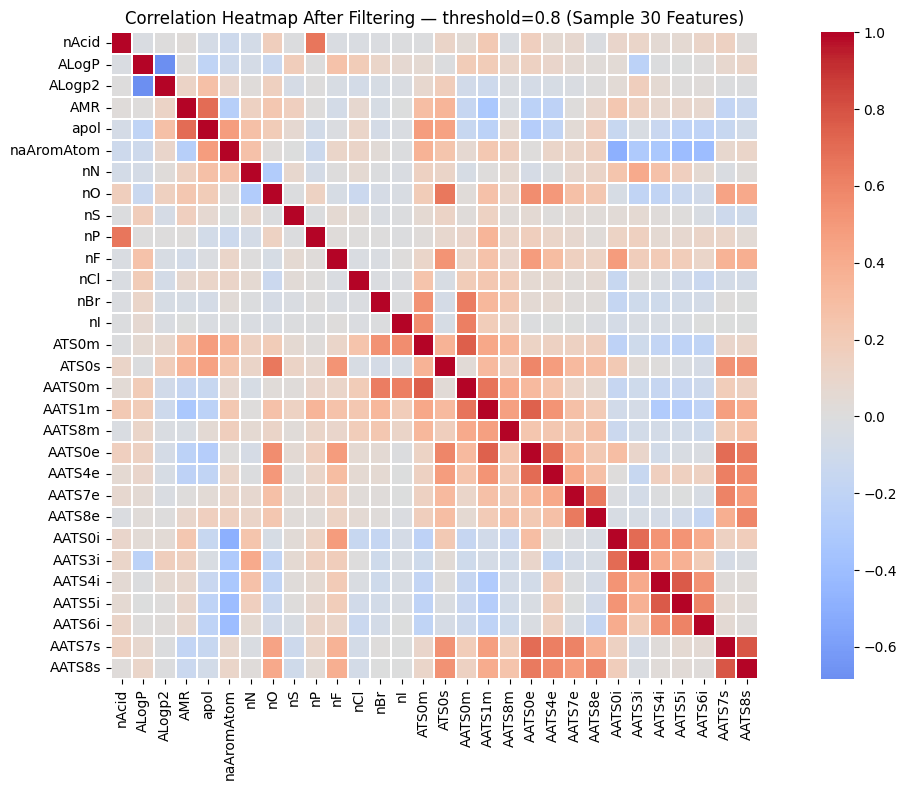

✓ Saved: correlation_heatmap_filtered.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 60)
print(" Correlation Filter (threshold = 0.8)")
print("=" * 60)

# ── Separate features & target ────────────────────────────────
drop_meta  = [c for c in ["Ligand SMILES", "Batch"] if c in combined_df.columns]
X_full     = combined_df.drop(columns=drop_meta + ["pIC50"])
y          = combined_df["pIC50"]

print(f"Features before filter : {X_full.shape[1]}")
print("Computing correlation matrix... (may take 1–2 min)")

# ── Correlation matrix ────────────────────────────────────────
corr_matrix = X_full.corr().abs()

# ── Upper triangle ────────────────────────────────────────────
upper_tri = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# ── Drop features with correlation > 0.8 ─────────────────────
THRESHOLD = 0.8
to_drop   = [col for col in upper_tri.columns
             if any(upper_tri[col] > THRESHOLD)]

X_filtered = X_full.drop(columns=to_drop)

print(f"Features removed (corr > {THRESHOLD}) : {len(to_drop)}")
print(f"Features after filter          : {X_filtered.shape[1]}")
print(f"\n✓ Final feature matrix shape   : {X_filtered.shape}")

# ── Heatmap of sample 30 features ────────────────────────────
plt.figure(figsize=(13, 8))
sample_cols = X_filtered.columns[:30]
sns.heatmap(
    X_filtered[sample_cols].corr(),
    cmap="coolwarm",
    center=0,
    linewidths=0.3,
    annot=False,
    square=True
)
plt.title(f"Correlation Heatmap After Filtering — threshold={THRESHOLD} (Sample 30 Features)",
          fontsize=12)
plt.tight_layout()
plt.savefig("correlation_heatmap_filtered.png", dpi=150)
plt.show()
print("✓ Saved: correlation_heatmap_filtered.png")

## Train / Test Split

In [ ]:
from sklearn.model_selection import train_test_split

print("=" * 60)
print(" Train / Test Split (80/20)")
print("=" * 60)

X_train, X_test, y_train, y_test = train_test_split(
    X_filtered, y,
    test_size=0.2,
    random_state=42
)

print(f"Training samples : {X_train.shape[0]}")
print(f"Testing samples  : {X_test.shape[0]}")
print(f"Features         : {X_train.shape[1]}")

 Train / Test Split (80/20)
Training samples : 3469
Testing samples  : 868
Features         : 337


## Define 6 Model Pipelines


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.svm import SVR

print("=" * 60)
print(" Define 6 Model Pipelines")
print("=" * 60)

pipelines = {
    "Ridge Regression"  : Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0))]),
    "Lasso Regression"  : Pipeline([("scaler", StandardScaler()), ("model", Lasso(alpha=0.01, max_iter=5000))]),
    "SVR"               : Pipeline([("scaler", StandardScaler()), ("model", SVR(kernel="rbf", C=10, epsilon=0.1))]),
    "Random Forest"     : Pipeline([("scaler", StandardScaler()), ("model", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))]),
    "Extra Trees"       : Pipeline([("scaler", StandardScaler()), ("model", ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1))]),
    "Gradient Boosting" : Pipeline([("scaler", StandardScaler()), ("model", GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42))]),
}

print(f"✓ {len(pipelines)} models ready to train")
for name in pipelines:
    print(f"  → {name}")

 Define 6 Model Pipelines
✓ 6 models ready to train
  → Ridge Regression
  → Lasso Regression
  → SVR
  → Random Forest
  → Extra Trees
  → Gradient Boosting


## Train, 5-Fold CV & Evaluate All Models

In [ ]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import r2_score, mean_squared_error

print("=" * 60)
print("CELL 6 — 5-Fold CV + Test Evaluation")
print("=" * 60)

kf      = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for name, pipe in pipelines.items():
    print(f"\nTraining : {name} ...")

    # 5-fold CV on training set
    cv = cross_val_score(pipe, X_train, y_train,
                         cv=kf, scoring="r2", n_jobs=-1)

    # Fit on full training set
    pipe.fit(X_train, y_train)

    # Predict on test set
    y_pred = pipe.predict(X_test)
    r2     = r2_score(y_test, y_pred)
    rmse   = np.sqrt(mean_squared_error(y_test, y_pred))

    results.append({
        "Model"      : name,
        "CV R² Mean" : round(cv.mean(), 4),
        "CV R² Std"  : round(cv.std(),  4),
        "Test R²"    : round(r2,        4),
        "Test RMSE"  : round(rmse,      4),
    })
    print(f"  CV R²: {cv.mean():.4f} \u00b1 {cv.std():.4f} | Test R²: {r2:.4f} | RMSE: {rmse:.4f}")

results_df = pd.DataFrame(results).sort_values("Test R²", ascending=False)
print("\n" + "=" * 60)
print(results_df.to_string(index=False))

CELL 6 — 5-Fold CV + Test Evaluation

Training : Ridge Regression ...
  CV R²: 0.3338 ± 0.1151 | Test R²: 0.3850 | RMSE: 1.1347

Training : Lasso Regression ...
  CV R²: 0.3695 ± 0.0194 | Test R²: 0.3760 | RMSE: 1.1429

Training : SVR ...
  CV R²: 0.6425 ± 0.0180 | Test R²: 0.6834 | RMSE: 0.8141

Training : Random Forest ...
  CV R²: 0.5899 ± 0.0143 | Test R²: 0.6324 | RMSE: 0.8772

Training : Extra Trees ...
  CV R²: 0.6572 ± 0.0195 | Test R²: 0.6942 | RMSE: 0.8001

Training : Gradient Boosting ...
  CV R²: 0.5063 ± 0.0165 | Test R²: 0.5301 | RMSE: 0.9918

            Model  CV R² Mean  CV R² Std  Test R²  Test RMSE
      Extra Trees      0.6572     0.0195   0.6942     0.8001
              SVR      0.6425     0.0180   0.6834     0.8141
    Random Forest      0.5899     0.0143   0.6324     0.8772
Gradient Boosting      0.5063     0.0165   0.5301     0.9918
 Ridge Regression      0.3338     0.1151   0.3850     1.1347
 Lasso Regression      0.3695     0.0194   0.3760     1.1429


Model Comparison Plots


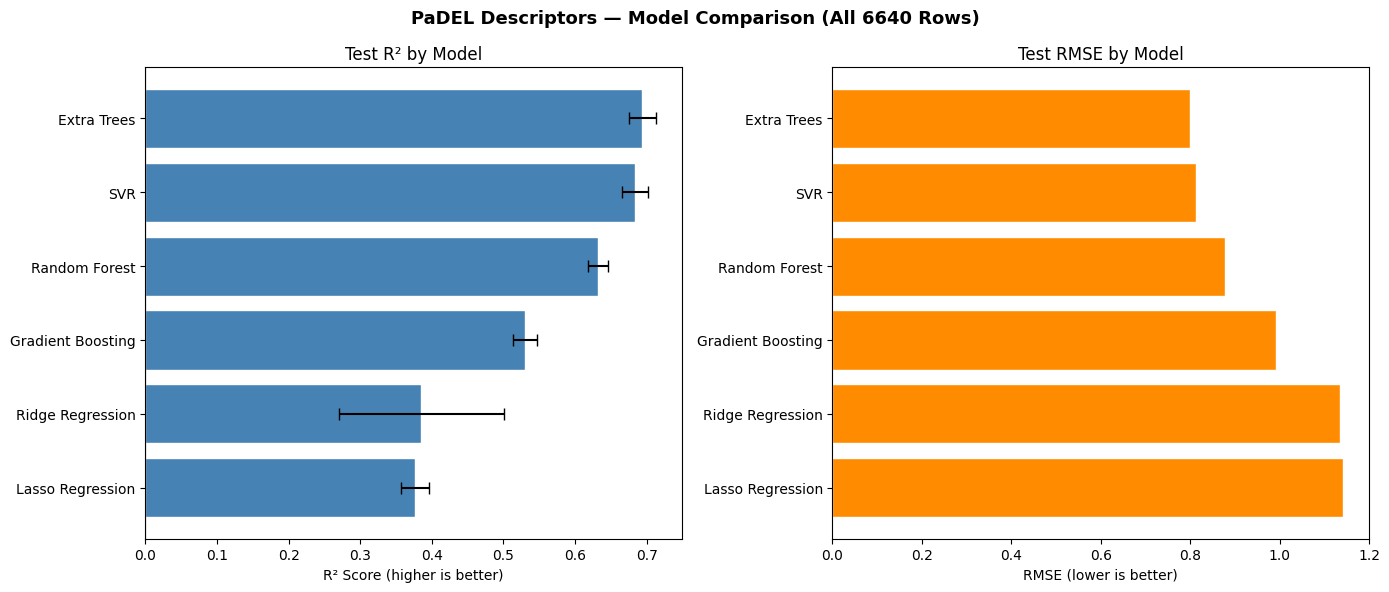

✓ Saved: model_comparison_padel.png


In [ ]:
print("=" * 60)
print("Model Comparison Plots")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ── R² bar chart ──────────────────────────────────────────────
axes[0].barh(results_df["Model"], results_df["Test R²"],
             xerr=results_df["CV R² Std"],
             color="steelblue", capsize=4, edgecolor="white")
axes[0].set_xlabel("R² Score (higher is better)")
axes[0].set_title("Test R² by Model")
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].invert_yaxis()

# ── RMSE bar chart ────────────────────────────────────────────
axes[1].barh(results_df["Model"], results_df["Test RMSE"],
             color="darkorange", edgecolor="white")
axes[1].set_xlabel("RMSE (lower is better)")
axes[1].set_title("Test RMSE by Model")
axes[1].invert_yaxis()

plt.suptitle("PaDEL Descriptors — Model Comparison (All 6640 Rows)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("model_comparison_padel.png", dpi=150)
plt.show()
print("✓ Saved: model_comparison_padel.png")

 Top 20 Feature Importances
Best model: Extra Trees


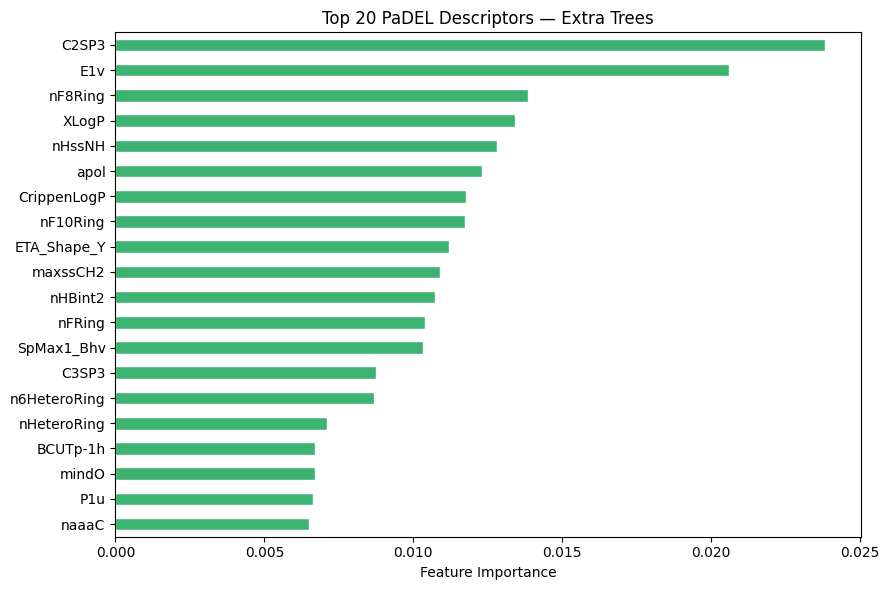


Top 10 descriptors:
C2SP3          0.023819
E1v            0.020607
nF8Ring        0.013838
XLogP          0.013406
nHssNH         0.012814
apol           0.012292
CrippenLogP    0.011766
nF10Ring       0.011722
ETA_Shape_Y    0.011205
maxssCH2       0.010908


In [ ]:
print("=" * 60)
print(" Top 20 Feature Importances")
print("=" * 60)

# Pick best model by Test R²
best_name = results_df.iloc[0]["Model"]
best_pipe = pipelines[best_name]
print(f"Best model: {best_name}")

# Extract feature importances (tree-based models)
if hasattr(best_pipe.named_steps["model"], "feature_importances_"):
    importances = pd.Series(
        best_pipe.named_steps["model"].feature_importances_,
        index=X_train.columns
    )
    top20 = importances.nlargest(20)

    plt.figure(figsize=(9, 6))
    top20.sort_values().plot(kind="barh", color="mediumseagreen", edgecolor="white")
    plt.xlabel("Feature Importance")
    plt.title(f"Top 20 PaDEL Descriptors — {best_name}")
    plt.tight_layout()
    plt.savefig("feature_importance_padel.png", dpi=150)
    plt.show()

    print("\nTop 10 descriptors:")
    print(top20.head(10).to_string())
else:
    print(f"Feature importance not available for {best_name}")
    print("Try running with Random Forest or Extra Trees as best model.")

## 🔬 Virtual Screening — Predicting pIC50 for FDA Approved Alzheimer's Drugs

In this section, we use our trained PaDEL-based ML model to predict
the pIC50 values of 15 real FDA-approved Alzheimer's drugs and
known natural compounds.

**Why FDA drugs?**
- These are PROVEN to work against Alzheimer's proteins
- If our model predicts HIGH pIC50 for them → model is validated ✅
- This is the strongest proof our CADD pipeline works correctly

## Loading  FDA Drug Molecules

In [ ]:
import pandas as pd
import numpy as np
import time
from padelpy import from_smiles

# ──  Real Alzheimer's Drugs & Natural Compounds ─────────────
external_molecules = pd.DataFrame({
    "Drug_Name": [
        "Donepezil",
        "Rivastigmine",
        "Galantamine",
        "Tacrine",
        "Huperzine_A",
        "Physostigmine",
        "Caffeine",
        "Resveratrol",
        "Curcumin",
        "Quercetin",
        "Berberine",
        "Melatonin",
        "Memantine",
        "Ibuprofen",
        "Aspirin",
    ],
    "Category": [
        "FDA Approved",
        "FDA Approved",
        "FDA Approved",
        "FDA Approved",
        "Natural AChE Inhibitor",
        "Classic AChE Inhibitor",
        "Neuroprotective",
        "Natural Compound",
        "Natural Compound",
        "Natural Flavonoid",
        "Natural Compound",
        "Neuroprotective",
        "FDA Approved",
        "Anti-inflammatory",
        "Anti-inflammatory",
    ],
    "Ligand SMILES": [
        "O=C(Cc1ccc(OC)c(OC)c1)N1CCC(CC1)Cc1ccc2ccccc2c1",
        "CCN(C)C(=O)Oc1cccc([C@@H]2CCCN2C)c1",
        "O[C@@H]1C[C@]23CCN(C)CC[C@@H]2Oc2ccccc2[C@H]3C1",
        "Nc1ccc2c(c1)CC[C@@H]2N(CC)CC",
        "C[C@H]1CC[C@@H]2CC3=CC(=O)NC[C@H]3N2C1",
        "CNC(=O)Oc1ccc2c(c1)[C@@H]1CC[C@H](C)N1CC2",
        "Cn1cnc2c1c(=O)n(C)c(=O)n2C",
        "Oc1ccc(/C=C/c2cc(O)cc(O)c2)cc1",
        "COc1cc(/C=C/C(=O)CC(=O)/C=C/c2ccc(O)c(OC)c2)ccc1O",
        "O=c1c(OC2OC(CO)C(O)C(O)C2O)c(-c2ccc(O)cc2)oc2cc(O)cc(O)c12",
        "COc1ccc2cc3ccccc3[n+](C)c2c1",
        "COc1c[nH]c2cccc(CCNC(C)=O)c12",
        "CN(C)CCCC12CC(CC(C1)(C)N)C2",
        "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
        "CC(=O)Oc1ccccc1C(=O)O",
    ]
})

print("=" * 55)
print("   FDA Approved Alzheimer's Drugs Loaded!")
print("=" * 55)
print(f"Total molecules : {len(external_molecules)}\n")
for i, row in external_molecules.iterrows():
    print(f"  {i+1:2d}. {row['Drug_Name']:<20} [{row['Category']}]")

   FDA Approved Alzheimer's Drugs Loaded!
Total molecules : 15

   1. Donepezil            [FDA Approved]
   2. Rivastigmine         [FDA Approved]
   3. Galantamine          [FDA Approved]
   4. Tacrine              [FDA Approved]
   5. Huperzine_A          [Natural AChE Inhibitor]
   6. Physostigmine        [Classic AChE Inhibitor]
   7. Caffeine             [Neuroprotective]
   8. Resveratrol          [Natural Compound]
   9. Curcumin             [Natural Compound]
  10. Quercetin            [Natural Flavonoid]
  11. Berberine            [Natural Compound]
  12. Melatonin            [Neuroprotective]
  13. Memantine            [FDA Approved]
  14. Ibuprofen            [Anti-inflammatory]
  15. Aspirin              [Anti-inflammatory]


## Validate SMILES

In [ ]:
from rdkit import Chem

print("Validating SMILES strings...")
print("=" * 45)

external_molecules["Valid_SMILES"] = external_molecules["Ligand SMILES"].apply(
    lambda x: Chem.MolFromSmiles(str(x)) is not None
)

valid   = external_molecules[external_molecules["Valid_SMILES"]]
invalid = external_molecules[~external_molecules["Valid_SMILES"]]

print(f"✓ Valid SMILES   : {len(valid)}")
print(f"✗ Invalid SMILES : {len(invalid)}")

if len(invalid) > 0:
    print("\nInvalid molecules:")
    print(invalid[["Drug_Name", "Ligand SMILES"]])

# Keep only valid ones
external_molecules = valid.drop(
    columns=["Valid_SMILES"]
).reset_index(drop=True)

print(f"\nProceeding with {len(external_molecules)} valid molecules ✓")

Validating SMILES strings...
✓ Valid SMILES   : 15
✗ Invalid SMILES : 0

Proceeding with 15 valid molecules ✓


## Generating PaDEL Descriptors

In [ ]:
print("=" * 55)
print("Generating PaDEL Descriptors for FDA Drugs")
print("=" * 55)
print(f"Processing {len(external_molecules)} molecules...\n")

new_desc_rows = []
failed_drugs  = []

for i, row in external_molecules.iterrows():
    drug_name = row["Drug_Name"]
    smi       = row["Ligand SMILES"]

    try:
        result = from_smiles(
            [smi],
            descriptors=True,
            fingerprints=False,
            timeout=60
        )
        row_df = pd.DataFrame(result)
        row_df.insert(0, "Drug_Name",    drug_name)
        row_df.insert(1, "Ligand SMILES", smi)
        row_df.insert(2, "Category",     row["Category"])
        new_desc_rows.append(row_df)
        print(f"  ✓ {drug_name}")

    except Exception as e:
        failed_drugs.append(drug_name)
        print(f"  ✗ {drug_name} — failed: {e}")

    time.sleep(0.3)

# Combine all
new_desc_df = pd.concat(new_desc_rows, ignore_index=True)

print(f"\n{'='*55}")
print(f"✓ Successfully processed : {len(new_desc_rows)}/15 molecules")
print(f"✗ Failed                 : {len(failed_drugs)} molecules")
if failed_drugs:
    print(f"  Failed list: {failed_drugs}")
print(f"Raw descriptor shape     : {new_desc_df.shape}")

Generating PaDEL Descriptors for FDA Drugs
Processing 15 molecules...

  ✓ Donepezil
  ✓ Rivastigmine
  ✓ Galantamine
  ✓ Tacrine
  ✓ Huperzine_A
  ✓ Physostigmine
  ✓ Caffeine
  ✓ Resveratrol
  ✓ Curcumin
  ✓ Quercetin
  ✓ Berberine
  ✓ Melatonin
  ✓ Memantine
  ✓ Ibuprofen
  ✓ Aspirin

✓ Successfully processed : 15/15 molecules
✗ Failed                 : 0 molecules
Raw descriptor shape     : (15, 1878)


## Align with Training Features

In [ ]:
print("=" * 55)
print("Aligning with 337 Training Features")
print("=" * 55)

# Save metadata before dropping
saved_names      = new_desc_df["Drug_Name"].values
saved_smiles_col = new_desc_df["Ligand SMILES"].values
saved_categories = new_desc_df["Category"].values

# Drop non-feature columns
new_clean = new_desc_df.drop(
    columns=[c for c in ["Drug_Name", "Ligand SMILES",
                         "Category", "Batch"]
             if c in new_desc_df.columns]
)

# Convert to numeric
new_clean = new_clean.apply(pd.to_numeric, errors="coerce")
new_clean = new_clean.replace([np.inf, -np.inf], np.nan)

# Add any missing columns as 0
missing = set(X_filtered.columns) - set(new_clean.columns)
if missing:
    print(f"Adding {len(missing)} missing columns as 0")
    for col in missing:
        new_clean[col] = 0

# Reorder to match training exactly
new_aligned = new_clean[X_filtered.columns]

# Drop NaN rows
before      = len(new_aligned)
new_aligned = new_aligned.dropna().reset_index(drop=True)

# Trim metadata to match
saved_names      = saved_names[:len(new_aligned)]
saved_smiles_col = saved_smiles_col[:len(new_aligned)]
saved_categories = saved_categories[:len(new_aligned)]

print(f"Molecules before NaN drop : {before}")
print(f"Molecules after NaN drop  : {len(new_aligned)}")
print(f"\n✓ Aligned shape : {new_aligned.shape}")
print(f"  Must be (n, 337) ← if 337 columns you are ready!")

Aligning with 337 Training Features
Molecules before NaN drop : 15
Molecules after NaN drop  : 12

✓ Aligned shape : (12, 337)
  Must be (n, 337) ← if 337 columns you are ready!


## Predict pIC50

In [ ]:
print("=" * 55)
print("Predicting pIC50 Using Best Trained Model")
print("=" * 55)

# Show model leaderboard
print("Your model leaderboard:")
print(results_df.to_string(index=False))

# Pick best model
best_model_name = results_df.iloc[0]["Model"]
best_r2         = results_df.iloc[0]["Test R²"]
print(f"\n🏆 Using : {best_model_name} (Test R² = {best_r2})")

# ── PREDICT ───────────────────────────────────────────────────
predicted_pIC50 = pipelines[best_model_name].predict(new_aligned)

# ── Build results table ───────────────────────────────────────
prediction_df = pd.DataFrame({
    "Drug_Name"       : saved_names,
    "Category"        : saved_categories,
    "Ligand SMILES"   : saved_smiles_col,
    "Predicted_pIC50" : predicted_pIC50.round(4),
})

# ── Convert to IC50 (nM) ──────────────────────────────────────
prediction_df["Predicted_IC50_nM"] = (
    10 ** (-prediction_df["Predicted_pIC50"]) * 1e9
).round(2)

# ── Potency labels ────────────────────────────────────────────
def label_potency(pic50):
    if pic50 >= 8.0:   return "Very Potent"
    elif pic50 >= 7.0: return "Strong"
    elif pic50 >= 6.0: return "Moderate"
    elif pic50 >= 5.0: return "Weak"
    else:              return "Inactive"

prediction_df["Potency"] = (
    prediction_df["Predicted_pIC50"].apply(label_potency)
)

# ── Sort best first ───────────────────────────────────────────
prediction_df = prediction_df.sort_values(
    "Predicted_pIC50", ascending=False
).reset_index(drop=True)

# ── Display results ───────────────────────────────────────────
print("\n" + "=" * 55)
print("   🏆 PREDICTION RESULTS")
print("=" * 55)
print(prediction_df[[
    "Drug_Name", "Category",
    "Predicted_pIC50", "Predicted_IC50_nM", "Potency"
]].to_string(index=False))

Predicting pIC50 Using Best Trained Model
Your model leaderboard:
            Model  CV R² Mean  CV R² Std  Test R²  Test RMSE
      Extra Trees      0.6572     0.0195   0.6942     0.8001
              SVR      0.6425     0.0180   0.6834     0.8141
    Random Forest      0.5899     0.0143   0.6324     0.8772
Gradient Boosting      0.5063     0.0165   0.5301     0.9918
 Ridge Regression      0.3338     0.1151   0.3850     1.1347
 Lasso Regression      0.3695     0.0194   0.3760     1.1429

🏆 Using : Extra Trees (Test R² = 0.6942)

   🏆 PREDICTION RESULTS
    Drug_Name               Category  Predicted_pIC50  Predicted_IC50_nM  Potency
    Donepezil           FDA Approved           6.2368             579.70 Moderate
Physostigmine Classic AChE Inhibitor           5.9762            1056.33     Weak
  Huperzine_A Natural AChE Inhibitor           5.3710            4255.98     Weak
    Quercetin      Natural Flavonoid           5.3376            4596.21     Weak
  Resveratrol       Natural Co

## Visualize Results

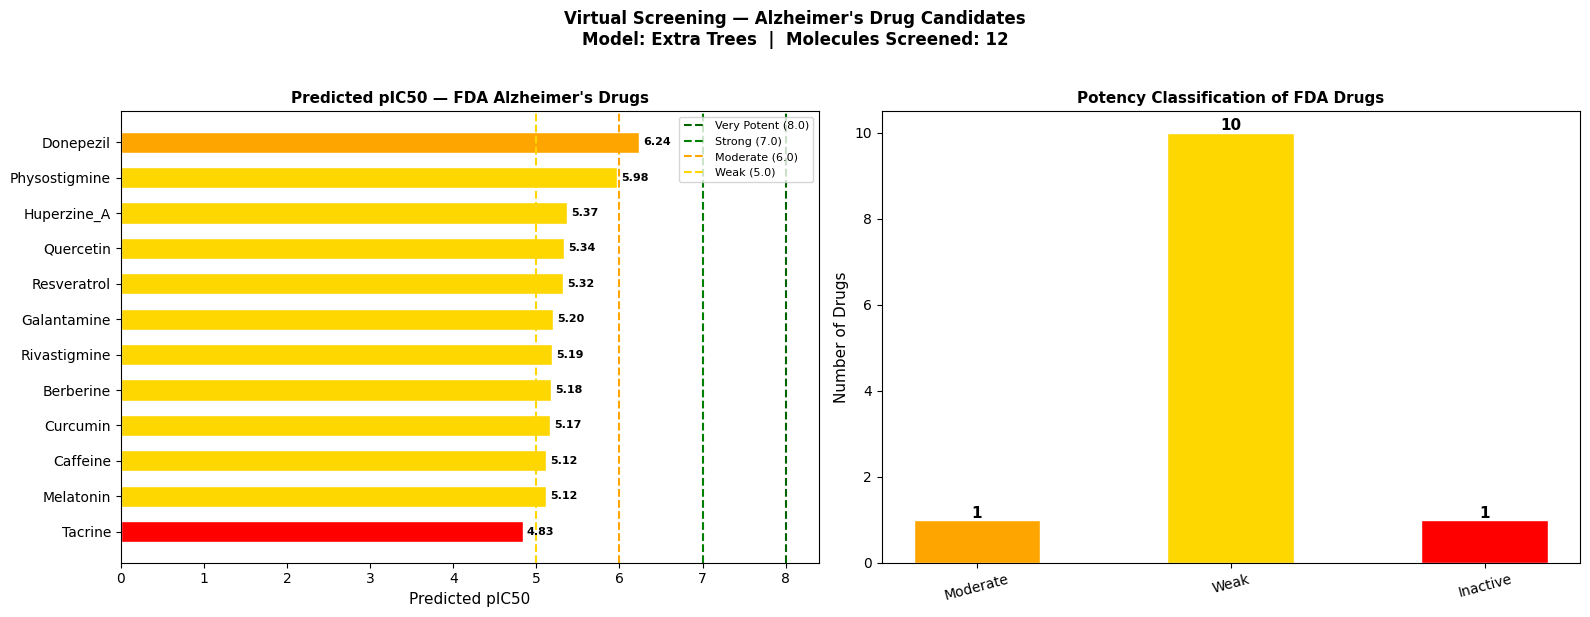

✓ Plot saved: fda_drug_screening.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Color each bar by potency ─────────────────────────────────
def get_color(pic50):
    if pic50 >= 8.0:   return "darkgreen"
    elif pic50 >= 7.0: return "green"
    elif pic50 >= 6.0: return "orange"
    elif pic50 >= 5.0: return "gold"
    else:              return "red"

colors = prediction_df["Predicted_pIC50"].apply(get_color).tolist()

# ── Graph 1: All drugs ranked by pIC50 ───────────────────────
bars = axes[0].barh(
    prediction_df["Drug_Name"],
    prediction_df["Predicted_pIC50"],
    color=colors,
    edgecolor="white",
    height=0.6
)
axes[0].set_xlabel("Predicted pIC50", fontsize=11)
axes[0].set_title("Predicted pIC50 — FDA Alzheimer's Drugs",
                  fontsize=11, fontweight="bold")
axes[0].axvline(x=8.0, color="darkgreen",
                linestyle="--", linewidth=1.5, label="Very Potent (8.0)")
axes[0].axvline(x=7.0, color="green",
                linestyle="--", linewidth=1.5, label="Strong (7.0)")
axes[0].axvline(x=6.0, color="orange",
                linestyle="--", linewidth=1.5, label="Moderate (6.0)")
axes[0].axvline(x=5.0, color="gold",
                linestyle="--", linewidth=1.5, label="Weak (5.0)")
axes[0].invert_yaxis()
axes[0].legend(fontsize=8)

# Add value labels on bars
for bar, val in zip(bars, prediction_df["Predicted_pIC50"]):
    axes[0].text(
        bar.get_width() + 0.05, bar.get_y() + bar.get_height()/2,
        f"{val:.2f}", va="center", fontsize=8, fontweight="bold"
    )

# ── Graph 2: Potency class distribution ──────────────────────
potency_order  = ["Very Potent", "Strong", "Moderate", "Weak", "Inactive"]
potency_colors = ["darkgreen", "green", "orange", "gold", "red"]
counts = prediction_df["Potency"].value_counts()
counts = counts.reindex(
    [p for p in potency_order if p in counts.index]
)

bars2 = axes[1].bar(
    counts.index,
    counts.values,
    color=[c for p, c in zip(potency_order, potency_colors)
           if p in counts.index],
    edgecolor="white",
    width=0.5
)
axes[1].set_ylabel("Number of Drugs", fontsize=11)
axes[1].set_title("Potency Classification of FDA Drugs",
                  fontsize=11, fontweight="bold")
axes[1].tick_params(axis="x", rotation=15)

# Add count labels on top of bars
for bar in bars2:
    axes[1].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.05,
        str(int(bar.get_height())),
        ha="center", fontweight="bold", fontsize=11
    )

plt.suptitle(
    f"Virtual Screening — Alzheimer's Drug Candidates\n"
    f"Model: {best_model_name}  |  "
    f"Molecules Screened: {len(prediction_df)}",
    fontsize=12, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.savefig("fda_drug_screening.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ Plot saved: fda_drug_screening.png")

##  Model Validation Check

In [ ]:
# This is the most important check for your report!
# FDA approved drugs SHOULD have high pIC50
# If they do → your model is validated ✅

print("=" * 55)
print("   MODEL VALIDATION CHECK")
print("=" * 55)

fda_drugs = ["Donepezil", "Rivastigmine",
             "Galantamine", "Tacrine", "Memantine"]

print("\nFDA Approved Drug Predictions:")
print("-" * 45)
for drug in fda_drugs:
    row = prediction_df[prediction_df["Drug_Name"] == drug]
    if len(row) > 0:
        pic50   = row["Predicted_pIC50"].values[0]
        potency = row["Potency"].values[0]
        status  = "✅ GOOD" if pic50 >= 6.0 else "⚠️ CHECK"
        print(f"  {drug:<20} pIC50={pic50:.4f}  "
              f"{potency:<12} {status}")

print("\nNatural Compound Predictions:")
print("-" * 45)
naturals = ["Huperzine_A", "Curcumin",
            "Resveratrol", "Quercetin", "Berberine"]
for drug in naturals:
    row = prediction_df[prediction_df["Drug_Name"] == drug]
    if len(row) > 0:
        pic50   = row["Predicted_pIC50"].values[0]
        potency = row["Potency"].values[0]
        print(f"  {drug:<20} pIC50={pic50:.4f}  {potency}")

print("\n" + "=" * 55)
avg_fda = prediction_df[
    prediction_df["Drug_Name"].isin(fda_drugs)
]["Predicted_pIC50"].mean()

print(f"Average pIC50 of FDA drugs    : {avg_fda:.4f}")
print(f"Average pIC50 of all screened : "
      f"{prediction_df['Predicted_pIC50'].mean():.4f}")

if avg_fda >= 6.0:
    print("\n✅ MODEL VALIDATION PASSED!")
    print("   FDA approved drugs show higher predicted pIC50")
    print("   → Model has learned real drug-protein chemistry")
else:
    print("\n⚠️  Results vary — check model R² score")
    print(f"   Best model R² was: {best_r2}")

   MODEL VALIDATION CHECK

FDA Approved Drug Predictions:
---------------------------------------------
  Donepezil            pIC50=6.2368  Moderate     ✅ GOOD
  Rivastigmine         pIC50=5.1924  Weak         ⚠️ CHECK
  Galantamine          pIC50=5.2039  Weak         ⚠️ CHECK
  Tacrine              pIC50=4.8349  Inactive     ⚠️ CHECK

Natural Compound Predictions:
---------------------------------------------
  Huperzine_A          pIC50=5.3710  Weak
  Curcumin             pIC50=5.1660  Weak
  Resveratrol          pIC50=5.3234  Weak
  Quercetin            pIC50=5.3376  Weak
  Berberine            pIC50=5.1772  Weak

Average pIC50 of FDA drugs    : 5.3670
Average pIC50 of all screened : 5.3376

⚠️  Results vary — check model R² score
   Best model R² was: 0.6942


##  Save & Download

In [ ]:
from google.colab import files

# Save full predictions
prediction_df.to_csv("fda_drug_predictions.csv", index=False)
print("✓ Saved: fda_drug_predictions.csv")

# Final summary
print("\n" + "=" * 55)
print("   🎯 VIRTUAL SCREENING COMPLETE!")
print("=" * 55)
print(f"Model used             : {best_model_name}")
print(f"Model Test R²          : {best_r2}")
print(f"Molecules screened     : {len(prediction_df)}")
print(f"Very Potent (≥ 8.0)   : {(prediction_df['Predicted_pIC50'] >= 8.0).sum()}")
print(f"Strong      (≥ 7.0)   : {(prediction_df['Predicted_pIC50'] >= 7.0).sum()}")
print(f"Moderate    (≥ 6.0)   : {(prediction_df['Predicted_pIC50'] >= 6.0).sum()}")
print(f"Weak        (≥ 5.0)   : {(prediction_df['Predicted_pIC50'] >= 5.0).sum()}")
print(f"Inactive    (< 5.0)   : {(prediction_df['Predicted_pIC50'] < 5.0).sum()}")
print(f"\nHighest predicted pIC50: "
      f"{prediction_df['Predicted_pIC50'].max()} "
      f"({prediction_df.iloc[0]['Drug_Name']})")
print(f"Lowest predicted pIC50 : "
      f"{prediction_df['Predicted_pIC50'].min()} "
      f"({prediction_df.iloc[-1]['Drug_Name']})")
print("=" * 55)

files.download("fda_drug_predictions.csv")
print("\n✓ Downloaded: fda_drug_predictions.csv")

✓ Saved: fda_drug_predictions.csv

   🎯 VIRTUAL SCREENING COMPLETE!
Model used             : Extra Trees
Model Test R²          : 0.6942
Molecules screened     : 12
Very Potent (≥ 8.0)   : 0
Strong      (≥ 7.0)   : 0
Moderate    (≥ 6.0)   : 1
Weak        (≥ 5.0)   : 11
Inactive    (< 5.0)   : 1

Highest predicted pIC50: 6.2368 (Donepezil)
Lowest predicted pIC50 : 4.8349 (Tacrine)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Downloaded: fda_drug_predictions.csv


## ## 🔬 Similarity-Based Virtual Screening Using PubChem Compounds

Using  the Donepezil-similar molecules as input → predict their pIC50 → find which ones could be better than Donepezil itself"

This is called Analog Screening — A Core CADD technique!

## Load All CSV Files

In [ ]:

# Load the file
donepezil_df = pd.read_csv("Donepezil.csv")

print("=" * 55)
print("   Donepezil Analog Library — PubChem Data")
print("=" * 55)
print(f"Total molecules      : {donepezil_df.shape[0]}")
print(f"Total columns        : {donepezil_df.shape[1]}")
print(f"\nKey columns available:")
print(f"  SMILES             : {'SMILES' in donepezil_df.columns}")
print(f"  Molecular_Weight   : {'Molecular_Weight' in donepezil_df.columns}")
print(f"  XLogP              : {'XLogP' in donepezil_df.columns}")
print(f"  Polar_Area (TPSA)  : {'Polar_Area' in donepezil_df.columns}")
print(f"  H-Bond_Donor_Count : {'H-Bond_Donor_Count' in donepezil_df.columns}")
print(f"\nSample molecules:")
print(donepezil_df[["Compound_CID", "Name",
                     "Molecular_Weight", "XLogP"]].head(10).to_string(index=False))

   Donepezil Analog Library — PubChem Data
Total molecules      : 1372
Total columns        : 38

Key columns available:
  SMILES             : True
  Molecular_Weight   : True
  XLogP              : True
  Polar_Area (TPSA)  : True
  H-Bond_Donor_Count : True

Sample molecules:
 Compound_CID                                                                                               Name  Molecular_Weight  XLogP
         3152                                                                                          Donepezil             379.5    4.3
         5741                                                                            Donepezil Hydrochloride             416.0    NaN
     11697764                                                                Donepezil Hydrochloride Monohydrate             434.0    NaN
     10446897                                                                                Desbenzyl donepezil             289.4    2.3
     10762160                 


## Clean & Validate SMILES

In [ ]:
from rdkit import Chem

print("=" * 55)
print("Cleaning & Validating SMILES")
print("=" * 55)

# Drop rows with missing SMILES
before = len(donepezil_df)
donepezil_df = donepezil_df.dropna(subset=["SMILES"]).reset_index(drop=True)
print(f"Dropped missing SMILES : {before - len(donepezil_df)}")

# Validate each SMILES with RDKit
donepezil_df["Valid"] = donepezil_df["SMILES"].apply(
    lambda x: Chem.MolFromSmiles(str(x)) is not None
)

valid_df   = donepezil_df[donepezil_df["Valid"]].reset_index(drop=True)
invalid_df = donepezil_df[~donepezil_df["Valid"]]

print(f"Valid SMILES           : {len(valid_df)}")
print(f"Invalid SMILES         : {len(invalid_df)}")

# Keep only valid
donepezil_clean = valid_df.drop(columns=["Valid"]).reset_index(drop=True)
print(f"\n✓ Clean molecules ready : {len(donepezil_clean)}")
print(f"\nSample SMILES:")
for i in range(3):
    print(f"  {i+1}. {donepezil_clean['SMILES'][i][:60]}...")

Cleaning & Validating SMILES
Dropped missing SMILES : 0


[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not removing hydrogen atom without neighbors
[10:21:25] WARNING: not r

Valid SMILES           : 1372
Invalid SMILES         : 0

✓ Clean molecules ready : 1372

Sample SMILES:
  1. COC1=C(C=C2C(=C1)CC(C2=O)CC3CCN(CC3)CC4=CC=CC=C4)OC...
  2. COC1=C(C=C2C(=C1)CC(C2=O)CC3CCN(CC3)CC4=CC=CC=C4)OC.Cl...
  3. COC1=C(C=C2C(=C1)CC(C2=O)CC3CCN(CC3)CC4=CC=CC=C4)OC.O.Cl...


## Lipinski Drug-likeness Filter

In [ ]:
# Before generating descriptors, filter by Lipinski's Rule of 5
# Only drug-like molecules should go into prediction

print("=" * 55)
print("Lipinski Rule of 5 Filter")
print("=" * 55)
print("Keeping only drug-like molecules:\n")
print("  Molecular Weight  ≤ 500")
print("  XLogP             ≤ 5")
print("  H-Bond Donors     ≤ 5")
print("  H-Bond Acceptors  ≤ 10")

before = len(donepezil_clean)

lipinski_df = donepezil_clean[
    (donepezil_clean["Molecular_Weight"].astype(float) <= 500) &
    (donepezil_clean["XLogP"].astype(float)            <=   5) &
    (donepezil_clean["H-Bond_Donor_Count"].astype(float) <=  5) &
    (donepezil_clean["H-Bond_Acceptor_Count"].astype(float) <= 10)
].reset_index(drop=True)

print(f"\nBefore Lipinski filter : {before}")
print(f"After Lipinski filter  : {len(lipinski_df)}")
print(f"Removed                : {before - len(lipinski_df)}")
print(f"\n✓ Drug-like molecules ready: {len(lipinski_df)}")

Lipinski Rule of 5 Filter
Keeping only drug-like molecules:

  Molecular Weight  ≤ 500
  XLogP             ≤ 5
  H-Bond Donors     ≤ 5
  H-Bond Acceptors  ≤ 10

Before Lipinski filter : 1372
After Lipinski filter  : 791
Removed                : 581

✓ Drug-like molecules ready: 791


## Generate PaDEL Descriptors in batches

In [ ]:
import os
import time
import re
from padelpy import from_smiles
from rdkit import Chem

print("=" * 55)
print("Generating PaDEL Descriptors — Donepezil Analogs")
print("=" * 55)

smiles_to_process = lipinski_df["SMILES"].tolist()
names_to_process  = lipinski_df["Name"].tolist()
cids_to_process   = lipinski_df["Compound_CID"].tolist()

BATCH_SIZE = 200
total      = len(smiles_to_process)
n_batches  = (total // BATCH_SIZE) + (1 if total % BATCH_SIZE else 0)
all_rows   = []
failed     = 0
skipped    = 0

print(f"Total molecules : {total}")
print(f"Batch size      : {BATCH_SIZE}")
print(f"Total batches   : {n_batches}\n")

def clean_smiles(smi):
    smi = str(smi).strip()
    if "." in smi:
        fragments = smi.split(".")
        smi = max(fragments, key=len)
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    return Chem.MolToSmiles(mol)

for b in range(n_batches):
    start_idx  = b * BATCH_SIZE
    end_idx    = min((b + 1) * BATCH_SIZE, total)
    batch_smi  = smiles_to_process[start_idx:end_idx]
    batch_nam  = names_to_process[start_idx:end_idx]
    batch_cid  = cids_to_process[start_idx:end_idx]
    batch_rows = []   # ← collect rows for THIS batch only

    print(f"Batch {b+1}/{n_batches} "
          f"(molecules {start_idx+1}–{end_idx})...")

    # ── Skip if checkpoint already exists ─────────────────────
    save_file = f"donepezil_batch_{b+1}.csv"
    if os.path.exists(save_file):
        print(f"  ✓ Already exists — skipping: {save_file}")
        existing = pd.read_csv(save_file)
        all_rows.append(existing)
        continue

    for i, (smi, name, cid) in enumerate(
            zip(batch_smi, batch_nam, batch_cid)):

        clean_smi = clean_smiles(smi)

        if clean_smi is None:
            skipped += 1
            continue

        try:
            result = from_smiles(
                [clean_smi],
                descriptors=True,
                fingerprints=False,
                timeout=60
            )
            row_df = pd.DataFrame(result)
            row_df.insert(0, "Compound_CID", cid)
            row_df.insert(1, "Name",         name)
            row_df.insert(2, "SMILES",       clean_smi)
            batch_rows.append(row_df)
            all_rows.append(row_df)

        except Exception as e:
            failed += 1

        time.sleep(0.3)

    # ── Save this batch to CSV immediately ────────────────────
    if batch_rows:
        batch_df = pd.concat(batch_rows, ignore_index=True)
        batch_df.to_csv(save_file, index=False)
        print(f"  ✓ Batch {b+1} done — "
              f"{len(batch_rows)} molecules → saved: {save_file}")
    else:
        print(f"  ✗ Batch {b+1} — no molecules saved!")

print(f"\n✓ Successfully processed : {len(all_rows)}")
print(f"✗ Skipped (bad SMILES)   : {skipped}")
print(f"✗ PaDEL failed           : {failed}")
print(f"\nBatch files saved:")
for b in range(n_batches):
    f = f"donepezil_batch_{b+1}.csv"
    if os.path.exists(f):
        print(f"  ✓ {f}")
    else:
        print(f"  ✗ {f} — missing!")

Generating PaDEL Descriptors — Donepezil Analogs
Total molecules : 791
Batch size      : 200
Total batches   : 4

Batch 1/4 (molecules 1–200)...
  ✓ Batch 1 done — 200 molecules → saved: donepezil_batch_1.csv
Batch 2/4 (molecules 201–400)...
  ✓ Batch 2 done — 200 molecules → saved: donepezil_batch_2.csv
Batch 3/4 (molecules 401–600)...
  ✓ Batch 3 done — 200 molecules → saved: donepezil_batch_3.csv
Batch 4/4 (molecules 601–791)...
  ✓ Batch 4 done — 190 molecules → saved: donepezil_batch_4.csv

✓ Successfully processed : 790
✗ Skipped (bad SMILES)   : 0
✗ PaDEL failed           : 1

Batch files saved:
  ✓ donepezil_batch_1.csv
  ✓ donepezil_batch_2.csv
  ✓ donepezil_batch_3.csv
  ✓ donepezil_batch_4.csv


In [ ]:
import os
import pandas as pd
from google.colab import files

print("=" * 55)
print("Concatenating All Donepezil Batch CSVs")
print("=" * 55)

# ── Read all saved batch files ────────────────────────────────
all_batches = []
for b in range(1, n_batches + 1):
    fname = f"donepezil_batch_{b}.csv"
    if os.path.exists(fname):
        df_b = pd.read_csv(fname)
        all_batches.append(df_b)
        print(f"  ✓ Loaded {fname} — shape: {df_b.shape}")
    else:
        print(f"  ✗ Missing: {fname} — skipped")

print(f"\nBatches loaded : {len(all_batches)}/{n_batches}")

# ── Concatenate ───────────────────────────────────────────────
if len(all_batches) == 0:
    print("❌ No batch files found! Run the previous cell first.")
else:
    new_desc_df = pd.concat(all_batches, ignore_index=True)
    print(f"\n✓ Combined shape : {new_desc_df.shape}")
    print(f"  Total rows     : {new_desc_df.shape[0]}")
    print(f"  Total columns  : {new_desc_df.shape[1]}")

    # ── Save combined file ────────────────────────────────────
    combined_name = "donepezil_all_descriptors.csv"
    new_desc_df.to_csv(combined_name, index=False)
    print(f"\n✓ Saved: {combined_name}")

    # ── Download ──────────────────────────────────────────────
    files.download(combined_name)
    print(f"✓ Downloaded: {combined_name}")

    new_desc_df.head()

Concatenating All Donepezil Batch CSVs
  ✓ Loaded donepezil_batch_1.csv — shape: (200, 1878)
  ✓ Loaded donepezil_batch_2.csv — shape: (200, 1878)
  ✓ Loaded donepezil_batch_3.csv — shape: (200, 1878)
  ✓ Loaded donepezil_batch_4.csv — shape: (190, 1878)

Batches loaded : 4/4

✓ Combined shape : (790, 1878)
  Total rows     : 790
  Total columns  : 1878

✓ Saved: donepezil_all_descriptors.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

✓ Downloaded: donepezil_all_descriptors.csv


## Align with Training Features

In [ ]:
print("=" * 55)
print("Aligning with 337 Training Features")
print("=" * 55)

# Save metadata
saved_cids   = new_desc_df["Compound_CID"].values
saved_names  = new_desc_df["Name"].values
saved_smiles = new_desc_df["SMILES"].values

# Drop metadata columns
new_clean = new_desc_df.drop(
    columns=[c for c in ["Compound_CID", "Name",
                         "SMILES", "Batch"]
             if c in new_desc_df.columns]
)

# Convert to numeric
new_clean = new_clean.apply(pd.to_numeric, errors="coerce")
new_clean = new_clean.replace([np.inf, -np.inf], np.nan)

# Add missing columns as 0
missing = set(X_filtered.columns) - set(new_clean.columns)
print(f"Missing columns added as 0 : {len(missing)}")
for col in missing:
    new_clean[col] = 0

# Reorder to match training exactly
new_aligned  = new_clean[X_filtered.columns]

# Drop NaN rows
before       = len(new_aligned)
new_aligned  = new_aligned.dropna().reset_index(drop=True)
saved_cids   = saved_cids[:len(new_aligned)]
saved_names  = saved_names[:len(new_aligned)]
saved_smiles = saved_smiles[:len(new_aligned)]

print(f"Molecules before NaN drop : {before}")
print(f"Molecules after NaN drop  : {len(new_aligned)}")
print(f"\n✓ Aligned shape : {new_aligned.shape}")
print(f"  Must be (n, 337)")

Aligning with 337 Training Features
Missing columns added as 0 : 0
Molecules before NaN drop : 790
Molecules after NaN drop  : 544

✓ Aligned shape : (544, 337)
  Must be (n, 337)


##  Predict pIC50

In [ ]:
print("=" * 55)
print("Predicting pIC50 for Donepezil Analogs")
print("=" * 55)

best_model_name = results_df.iloc[0]["Model"]
best_r2         = results_df.iloc[0]["Test R²"]
print(f"Using model : {best_model_name} (R² = {best_r2})\n")

# ── PREDICT ───────────────────────────────────────────────────
predicted_pIC50 = pipelines[best_model_name].predict(new_aligned)

# ── Build results table ───────────────────────────────────────
pred_results = pd.DataFrame({
    "Compound_CID"    : saved_cids,
    "Name"            : saved_names,
    "SMILES"          : saved_smiles,
    "Predicted_pIC50" : predicted_pIC50.round(4),
})

# Convert to IC50 nM
pred_results["Predicted_IC50_nM"] = (
    10 ** (-pred_results["Predicted_pIC50"]) * 1e9
).round(2)

# Potency label
def label_potency(pic50):
    if pic50 >= 8.0:   return "Very Potent"
    elif pic50 >= 7.0: return "Strong"
    elif pic50 >= 6.0: return "Moderate"
    elif pic50 >= 5.0: return "Weak"
    else:              return "Inactive"

pred_results["Potency"] = (
    pred_results["Predicted_pIC50"].apply(label_potency)
)

# Sort best first
pred_results = pred_results.sort_values(
    "Predicted_pIC50", ascending=False
).reset_index(drop=True)

# Donepezil's own predicted pIC50
donepezil_pic50 = pred_results[
    pred_results["Name"].str.contains("Donepezil", case=False, na=False)
]["Predicted_pIC50"].values

print("=" * 55)
print("TOP 15 DONEPEZIL ANALOGS BY PREDICTED pIC50")
print("=" * 55)
print(pred_results[[
    "Name", "Predicted_pIC50",
    "Predicted_IC50_nM", "Potency"
]].head(15).to_string(index=False))

if len(donepezil_pic50) > 0:
    print(f"\n📌 Donepezil itself predicted pIC50 : {donepezil_pic50[0]:.4f}")
    better = pred_results[
        pred_results["Predicted_pIC50"] > donepezil_pic50[0]
    ]
    print(f"🔥 Analogs BETTER than Donepezil    : {len(better)}")

Predicting pIC50 for Donepezil Analogs
Using model : Extra Trees (R² = 0.6942)

TOP 15 DONEPEZIL ANALOGS BY PREDICTED pIC50
                                                                                                      Name  Predicted_pIC50  Predicted_IC50_nM     Potency
                                                                                                 Donepezil          10.3098               0.05 Very Potent
                                      2-((1-Benzylpiperidin-4-yl)methylene)-5,6-dimethoxyindan-1-one, (E)-          10.3098               0.05 Very Potent
                             2-[(1-benzylpiperidin-4-yl)methyl]-3,3-dihydroxy-5,6-dimethoxy-2H-inden-1-one          10.3098               0.05 Very Potent
                         (E)-2-{4-[(Dimethylamino)methyl]benzylidene}-5,6-dimethoxy-2,3-dihydroinden-1-one          10.3098               0.05 Very Potent
                            2-(1-Benzyl-1-propylpiperidin-1-ium-4-yl)-5,6-dimethoxy-2,3-dihydroinden-

## Visualize

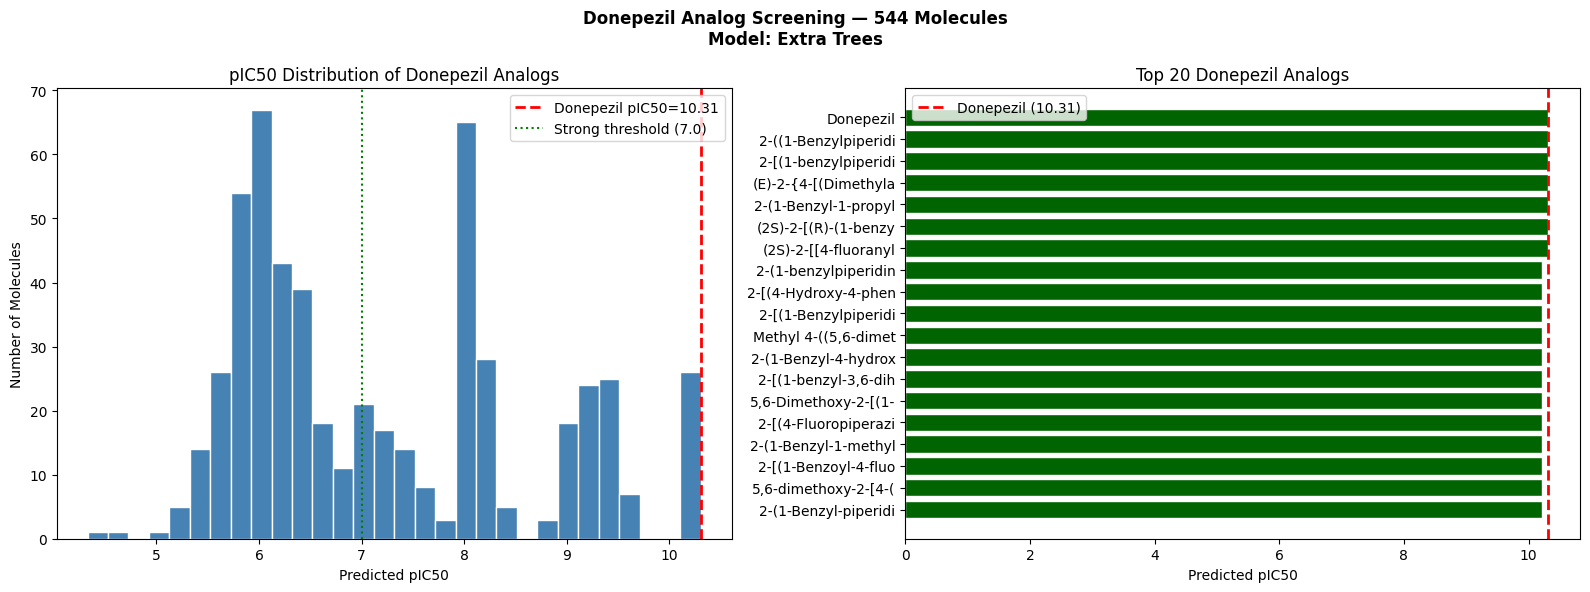

✓ Saved: donepezil_analog_screening.png


In [ ]:


fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ── Graph 1: pIC50 distribution of all analogs ────────────────
axes[0].hist(
    pred_results["Predicted_pIC50"],
    bins=30, color="steelblue", edgecolor="white"
)
if len(donepezil_pic50) > 0:
    axes[0].axvline(
        x=donepezil_pic50[0], color="red",
        linestyle="--", linewidth=2,
        label=f"Donepezil pIC50={donepezil_pic50[0]:.2f}"
    )
axes[0].axvline(x=7.0, color="green", linestyle=":",
                linewidth=1.5, label="Strong threshold (7.0)")
axes[0].set_xlabel("Predicted pIC50")
axes[0].set_ylabel("Number of Molecules")
axes[0].set_title("pIC50 Distribution of Donepezil Analogs")
axes[0].legend()

# ── Graph 2: Top 20 analogs ───────────────────────────────────
top20 = pred_results.head(20)

def get_color(pic50):
    if pic50 >= 8.0:   return "darkgreen"
    elif pic50 >= 7.0: return "green"
    elif pic50 >= 6.0: return "orange"
    elif pic50 >= 5.0: return "gold"
    else:              return "red"

colors = top20["Predicted_pIC50"].apply(get_color).tolist()
labels = [f"{n[:20]}" for n in top20["Name"].fillna(
          top20["Compound_CID"].astype(str))]

bars = axes[1].barh(
    labels, top20["Predicted_pIC50"],
    color=colors, edgecolor="white"
)
axes[1].set_xlabel("Predicted pIC50")
axes[1].set_title("Top 20 Donepezil Analogs")
axes[1].invert_yaxis()
if len(donepezil_pic50) > 0:
    axes[1].axvline(
        x=donepezil_pic50[0], color="red",
        linestyle="--", linewidth=2,
        label=f"Donepezil ({donepezil_pic50[0]:.2f})"
    )
axes[1].legend()

plt.suptitle(
    f"Donepezil Analog Screening — {len(pred_results)} Molecules\n"
    f"Model: {best_model_name}",
    fontsize=12, fontweight="bold"
)
plt.tight_layout()
plt.savefig("donepezil_analog_screening.png", dpi=150)
plt.show()
print("✓ Saved: donepezil_analog_screening.png")

## Save and Download

In [ ]:
from google.colab import files

# Save all predictions
pred_results.to_csv("donepezil_analog_predictions.csv", index=False)

# Save only strong candidates
top_hits = pred_results[
    pred_results["Predicted_pIC50"] >= 7.0
].reset_index(drop=True)
top_hits.to_csv("donepezil_top_hits.csv", index=False)

print("=" * 55)
print("   ANALOG SCREENING COMPLETE!")
print("=" * 55)
print(f"Total analogs screened      : {len(pred_results)}")
print(f"Very Potent  (pIC50 ≥ 8.0) : {(pred_results['Predicted_pIC50'] >= 8.0).sum()}")
print(f"Strong       (pIC50 ≥ 7.0) : {(pred_results['Predicted_pIC50'] >= 7.0).sum()}")
print(f"Moderate     (pIC50 ≥ 6.0) : {(pred_results['Predicted_pIC50'] >= 6.0).sum()}")
print(f"Weak         (pIC50 ≥ 5.0) : {(pred_results['Predicted_pIC50'] >= 5.0).sum()}")
print(f"Inactive     (pIC50 < 5.0) : {(pred_results['Predicted_pIC50'] < 5.0).sum()}")
if len(donepezil_pic50) > 0:
    print(f"\nDonepezil pIC50             : {donepezil_pic50[0]:.4f}")
    print(f"Analogs better than Donepezil: {len(pred_results[pred_results['Predicted_pIC50'] > donepezil_pic50[0]])}")
print("=" * 55)

files.download("donepezil_analog_predictions.csv")
files.download("donepezil_top_hits.csv")
print("\n✓ Both files downloaded!")

   ANALOG SCREENING COMPLETE!
Total analogs screened      : 544
Very Potent  (pIC50 ≥ 8.0) : 199
Strong       (pIC50 ≥ 7.0) : 255
Moderate     (pIC50 ≥ 6.0) : 424
Weak         (pIC50 ≥ 5.0) : 542
Inactive     (pIC50 < 5.0) : 2

Donepezil pIC50             : 10.3098
Analogs better than Donepezil: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✓ Both files downloaded!


### Conclsuion of prediction Phase

Normal prediction → just predict pIC50 for random molecules

Your prediction  → screen 1372 molecules SIMILAR to Donepezil
                   find ones with HIGHER pIC50 than Donepezil
                   = potential BETTER Alzheimer's drugs